In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree


import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import string

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


In [2]:
file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_with_incdec.parquet'
df = pd.read_parquet(file, engine='pyarrow')

In [3]:
df.head(7)

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
1,36.05,-91.15,NaN,2024-02-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
2,36.05,-91.15,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
3,36.05,-91.15,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
4,36.05,-91.15,NaN,2024-03-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
5,36.05,-91.15,NaN,2024-03-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
6,36.05,-91.15,NaN,2024-03-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class'],
      dtype='object')

# subset pulse starts

In [5]:
pulse_df = df[df["pulse_start"] == True].copy()

pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])
pulse_df = pulse_df.sort_values("datetime").reset_index(drop=True)

In [6]:
#defining thresholds
spatial_degree = 0.2 #~20 km (since 0.1° grid ~ 10 km)
time_hours = 24 #pulses within 1 day

In [9]:
pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

# time in hours since first pulse
pulse_df["time_num"] = (pulse_df["datetime"] - pulse_df["datetime"].min()).dt.total_seconds() /3600

# build tree only in spatial coordinates
spatial_coords = pulse_df[["grid_lat", "grid_lon"]].to_numpy()
tree =cKDTree(spatial_coords)

# candidate spatial neighbors within 0.2 degrees
candidate_pairs = tree.query_pairs(r=spatial_degree)

# keep only pairs also within 24 hours
valid_pairs = []
times = pulse_df["time_num"].to_numpy()

for i, j in candidate_pairs:
    if abs(times[i] - times[j]) <= time_hours:
        valid_pairs.append((i, j))

#union find to group connected comps 
parent = np.arange(len(pulse_df))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]  
        x = parent[x]
    return x

def union(x, y):
    parent[find(x)] = find(y)

for i, j in valid_pairs:
    union(i, j)

pulse_df["group_id"] = [find(i) for i in range(len(pulse_df))]

In [10]:
pulse_df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class',
       'time_num', 'group_id'],
      dtype='object')

In [11]:
output_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_grouped_2hour_pulses.parquet'
pulse_df.to_parquet(output_file, engine='pyarrow')

# EDA

In [12]:
"""
EXEMPLAR EVENT SELECTION
========================
Finds pulse events where:
  1. Precipitation clearly falls in the N days BEFORE the pulse (pre-window)
  2. NO2 observations exist on EVERY calendar day for M days AFTER the pulse (post-window)

Need`pulse_df` and `df` to be defined.
"""
# ──────────────────────────────────────────────
# TUNEABLE PARAMETERS
# ──────────────────────────────────────────────
PRE_DAYS          = 5      # How many days before the pulse to look for precip
POST_DAYS         = 5      # How many days after the pulse must have NO2 obs
MIN_PRECIP_MM     = 2.0    # Total precip (mm, summed over all cells × hours) needed in pre-window
MIN_EVENT_CELLS   = 3      # Ignore tiny single/dual-cell events
REQUIRED_NO2_DAYS = POST_DAYS   # Every one of the post-window days must have a NO2 reading
MIN_CELLS_PER_DAY = 1      # At least this many cells with non-NaN NO2 on each post day
NO2_PRE_DAYS  = 5   # days before pulse that must have NO2 obs
NO2_POST_DAYS = 5   # days after pulse that must have NO2 obs

# ──────────────────────────────────────────────
# 0. Prep
# ──────────────────────────────────────────────
df_ = df.copy()
df_["datetime"] = pd.to_datetime(df_["datetime"])
df_["date"] = df_["datetime"].dt.normalize()

pulse_df_ = pulse_df.copy()
pulse_df_["datetime"] = pd.to_datetime(pulse_df_["datetime"])


In [13]:
# ──────────────────────────────────────────────
# 1. Event-level metadata (size + start time)
# ──────────────────────────────────────────────
event_meta = (
    pulse_df_
    .groupby("group_id")
    .agg(
        n_cells   = ("grid_lat", "count"),
        t0        = ("datetime", "min"),
        centroid_lat = ("grid_lat", "mean"),
        centroid_lon = ("grid_lon", "mean"),
    )
    .reset_index()
)

# keep only events large enough to be interesting
event_meta = event_meta[event_meta["n_cells"] >= MIN_EVENT_CELLS].copy()
event_meta["t0"] = pd.to_datetime(event_meta["t0"])
event_meta["t0_date"] = event_meta["t0"].dt.normalize()

print(f"Candidate events (≥{MIN_EVENT_CELLS} cells): {len(event_meta)}")


Candidate events (≥3 cells): 149


In [14]:
# ──────────────────────────────────────────────
# 2. Score each event
# ──────────────────────────────────────────────
records = []

for _, row in event_meta.iterrows():
    eid  = row["group_id"]
    t0   = row["t0"]
    t0d  = row["t0_date"]

    event_cells = (
        pulse_df_[pulse_df_["group_id"] == eid][["grid_lat", "grid_lon"]]
        .drop_duplicates()
    )

    sub = df_.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner")

    # ── PRE-WINDOW: precipitation ────────────────
    pre = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=PRE_DAYS)) &
        (sub["datetime"] <  t0)
    ].copy()

    total_precip = pd.to_numeric(pre["h_precip_mm"], errors="coerce").sum()

    pre["date"] = pre["datetime"].dt.normalize()
    daily_precip = pre.groupby("date")["h_precip_mm"].apply(
        lambda x: pd.to_numeric(x, errors="coerce").sum()
    )
    n_precip_days = (daily_precip > 0.1).sum()

    # ── NO2 COVERAGE: 5 days before AND 5 days after ──
    no2_window = sub[
        (sub["date"] >= t0d - pd.Timedelta(days=NO2_PRE_DAYS)) &
        (sub["date"] <= t0d + pd.Timedelta(days=NO2_POST_DAYS)) &
        (sub["date"] != t0d)   # exclude the pulse day itself
    ].copy()

    daily_no2_cells = (
        no2_window.groupby("date")["no2_mean"]
        .apply(lambda x: x.notna().sum())
    )

    # expected dates: 5 before + 5 after (excluding pulse day)
    expected_dates = pd.date_range(
        t0d - pd.Timedelta(days=NO2_PRE_DAYS),
        t0d + pd.Timedelta(days=NO2_POST_DAYS),
        freq="D"
    ).normalize()
    expected_dates = expected_dates[expected_dates != t0d]

    covered_dates    = set(daily_no2_cells[daily_no2_cells >= MIN_CELLS_PER_DAY].index.normalize())
    all_days_covered = set(expected_dates).issubset(covered_dates)

    days_with_no2 = (daily_no2_cells >= MIN_CELLS_PER_DAY).sum()

    records.append({
        "group_id"            : eid,
        "n_cells"             : row["n_cells"],
        "t0"                  : t0,
        "centroid_lat"        : row["centroid_lat"],
        "centroid_lon"        : row["centroid_lon"],
        "total_precip_mm"     : round(total_precip, 2),
        "n_precip_days"       : int(n_precip_days),
        "days_with_no2"       : int(days_with_no2),
        "all_days_covered"    : all_days_covered,
    })

scored = pd.DataFrame(records)

In [15]:
# ──────────────────────────────────────────────
# 3. Apply the two main filters
# ──────────────────────────────────────────────
exemplars = scored[
    (scored["total_precip_mm"]  >= MIN_PRECIP_MM) &
    (scored["all_days_covered"] == True)
].copy()

exemplars = exemplars.sort_values(
    ["total_precip_mm", "n_cells"],
    ascending=False
).reset_index(drop=True)

print(f"\nExemplar events found: {len(exemplars)}")
print(f"  (precip ≥ {MIN_PRECIP_MM} mm in {PRE_DAYS} pre-days  AND  NO2 on all {NO2_PRE_DAYS} pre + {NO2_POST_DAYS} post days)\n")

print(exemplars[[
    "group_id", "t0", "n_cells",
    "centroid_lat", "centroid_lon",
    "total_precip_mm", "n_precip_days", "days_with_no2"
]].to_string(index=False))


Exemplar events found: 14
  (precip ≥ 2.0 mm in 5 pre-days  AND  NO2 on all 5 pre + 5 post days)

 group_id                  t0  n_cells  centroid_lat  centroid_lon  total_precip_mm  n_precip_days  days_with_no2
     1907 2024-07-13 15:00:00       26     40.288462    -98.926923           793.54              5             10
     1919 2024-07-12 16:00:00       29     40.243103    -97.553448           261.25              6             10
     1809 2024-07-09 15:00:00       15     40.776667    -95.963333           219.59              4             10
     1807 2024-07-09 15:00:00        5     40.250000    -96.730000            97.45              4             10
     1886 2024-07-13 15:00:00        4     39.700000    -98.800000            84.59              4             10
     1897 2024-07-13 15:00:00        7     40.050000    -98.192857            64.31              4             10
     1728 2024-07-08 15:00:00       15     40.743333    -99.910000            50.74              4     

/tmp/ipykernel_1222785/3372059560.py:372: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.02, 1, 0.99])


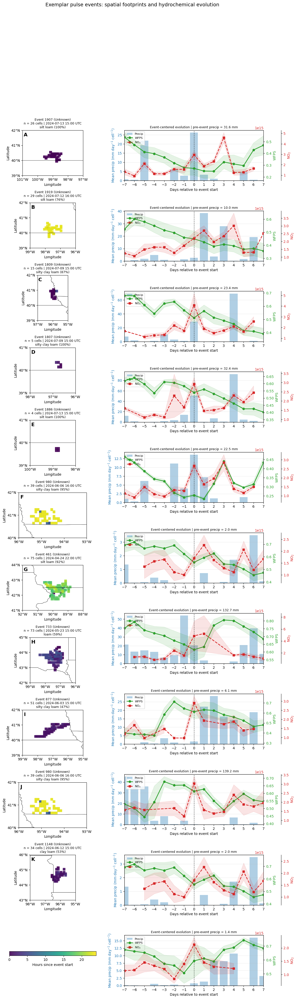

In [16]:
events_to_plot = [
    1907, 1919, 1809, 1807, 1886, 980,
    461, 733, 877, 980, 1148
]

WINDOW_DAYS = 7

# auto-generate enough panel labels
panel_labels = [
    f"{letter}{num if num > 0 else ''}"
    for num in range(10)
    for letter in string.ascii_uppercase
]

# -----------------------------
# Prep data
# -----------------------------
df = df.copy()
pulse_df = pulse_df.copy()

df["datetime"] = pd.to_datetime(df["datetime"])
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

# keep only events that actually exist
events_to_plot = [
    eid for eid in events_to_plot
    if eid in pulse_df["group_id"].unique()
]

n_events = len(events_to_plot)

# -----------------------------
# Figure setup
# -----------------------------
fig = plt.figure(figsize=(13, 4 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.6)

map_axes = []
last_sc = None

# global color range for hours since start
all_event_pulses = pulse_df[pulse_df["group_id"].isin(events_to_plot)].copy()
all_event_pulses["hours_since_start"] = (
    all_event_pulses["datetime"]
    - all_event_pulses.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600

vmin_time = 0
vmax_time = all_event_pulses["hours_since_start"].max()

# -----------------------------
# Loop through events
# -----------------------------
for row, eid in enumerate(events_to_plot):

    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2,
        subplot_spec=outer[row],
        width_ratios=[1.0, 1.6],
        wspace=0.25
    )

    # -----------------------------
    # Event data
    # -----------------------------
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # -----------------------------
    # Dominant soil texture
    # -----------------------------
    if "dominant_texture" in event_pulses.columns:
        event_soils = (
            event_pulses[["grid_lat", "grid_lon", "dominant_texture"]]
            .drop_duplicates(subset=["grid_lat", "grid_lon"])
            .dropna(subset=["dominant_texture"])
        )

        if len(event_soils) > 0:
            soil_counts = event_soils["dominant_texture"].value_counts()
            dominant_soil = soil_counts.index[0]
            dominant_soil_frac = soil_counts.iloc[0] / soil_counts.sum()
            soil_str = f"{dominant_soil} ({dominant_soil_frac:.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    # -----------------------------
    # SM class label, if available
    # -----------------------------
    try:
        sm_label = event_sm_frac.loc[eid, "dominant_class"]
    except Exception:
        sm_label = "Unknown"

    # -----------------------------
    # Pull ± window time series
    # -----------------------------
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()

    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    # -----------------------------
    # Daily aggregation by cell first
    # -----------------------------
    agg_cell = {
        "precip": ("h_precip_mm", "sum"),
        "no2": ("no2_mean", "mean"),
    }

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = (
        sub.groupby(["grid_lat", "grid_lon", "lag_day"])
        .agg(**agg_cell)
        .reset_index()
    )

    # -----------------------------
    # Then aggregate across event cells
    # -----------------------------
    agg_event = {
        "precip_mean": ("precip", "mean"),
        "precip_std": ("precip", "std"),
        "no2_mean": ("no2", "mean"),
        "no2_std": ("no2", "std"),
    }

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = (
        cell_daily.groupby("lag_day")
        .agg(**agg_event)
        .reset_index()
    )

    # Add missing lag days
    full_lags = pd.DataFrame({
        "lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)
    })

    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")

    # Fill precip only; leave NO2/WFPS as NaN
    event_daily["precip_mean"] = event_daily["precip_mean"].fillna(0)
    event_daily["precip_std"] = event_daily["precip_std"].fillna(0)

    # -----------------------------
    # Left panel: map
    # -----------------------------
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)

    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5

    ax_map.set_extent(
        [lon_min, lon_max, lat_min, lat_max],
        crs=ccrs.PlateCarree()
    )

    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)

    sc = ax_map.scatter(
        event_pulses["grid_lon"],
        event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"],
        cmap="viridis",
        vmin=vmin_time,
        vmax=vmax_time,
        s=45,
        marker="s",
        alpha=0.9,
        transform=ccrs.PlateCarree()
    )

    last_sc = sc

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())

    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")

    ax_map.text(
        0.02, 0.95,
        panel_labels[row],
        transform=ax_map.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top",
        ha="left"
    )

    title = (
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
    )

    if soil_str:
        title += f"\n{soil_str}"

    ax_map.set_title(title, fontsize=9)

    # -----------------------------
    # Right panel: time series
    # -----------------------------
    ax_ts = fig.add_subplot(inner[1])

    ax_ts.bar(
        event_daily["lag_day"],
        event_daily["precip_mean"],
        color="tab:blue",
        alpha=0.35,
        width=0.8,
        label="Precip"
    )

    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    # WFPS axis
    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()

        valid_wfps = event_daily["wfps_mean"].notna()

        ax_wfps.plot(
            event_daily.loc[valid_wfps, "lag_day"],
            event_daily.loc[valid_wfps, "wfps_mean"],
            color="tab:green",
            marker="o",
            linewidth=2,
            label="WFPS"
        )

        ax_wfps.fill_between(
            event_daily.loc[valid_wfps, "lag_day"],
            (
                event_daily["wfps_mean"] - event_daily["wfps_std"]
            ).loc[valid_wfps],
            (
                event_daily["wfps_mean"] + event_daily["wfps_std"]
            ).loc[valid_wfps],
            color="tab:green",
            alpha=0.12
        )

        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    # NO2 axis
    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))

    valid_no2 = event_daily["no2_mean"].notna()

    ax_no2.plot(
        event_daily.loc[valid_no2, "lag_day"],
        event_daily.loc[valid_no2, "no2_mean"],
        color="tab:red",
        linestyle="--",
        marker="s",
        linewidth=2,
        label="NO$_2$"
    )

    ax_no2.fill_between(
        event_daily.loc[valid_no2, "lag_day"],
        (
            event_daily["no2_mean"] - event_daily["no2_std"]
        ).loc[valid_no2],
        (
            event_daily["no2_mean"] + event_daily["no2_std"]
        ).loc[valid_no2],
        color="tab:red",
        alpha=0.12
    )

    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 1))
    ax_ts.set_xlabel("Days relative to event start")

    pre_precip = event_daily.loc[
        event_daily["lag_day"] < 0,
        "precip_mean"
    ].sum()

    ax_ts.set_title(
        f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm",
        fontsize=9
    )

    # Explicit legend handles
    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0], [0], color="tab:red", linestyle="--",
               marker="s", linewidth=2, label="NO$_2$")
    ]

    if has_wfps:
        handles.insert(
            1,
            Line2D([0], [0], color="tab:green",
                   marker="o", linewidth=2, label="WFPS")
        )

    ax_ts.legend(
        handles=handles,
        fontsize=8,
        loc="upper left",
        frameon=True
    )

# -----------------------------
# Shared colorbar
# -----------------------------
if last_sc is not None:
    cbar = fig.colorbar(
        last_sc,
        ax=map_axes,
        orientation="horizontal",
        fraction=0.04,
        pad=0.06
    )
    cbar.set_label("Hours since event start")

fig.suptitle(
    "Exemplar pulse events: spatial footprints and hydrochemical evolution",
    fontsize=14,
    y=0.995
)

plt.tight_layout(rect=[0, 0.02, 1, 0.99])

plt.savefig(
    "exemplar_events.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [17]:
event_summary = (
    pulse_df.groupby("group_id")
    .agg(
        n_cells=("grid_lat", "count"),
        mean_no2=("no2_mean", "mean"),
        max_no2=("no2_mean", "max"),
        std_no2=("no2_mean", "std"),
        start_time=("datetime", "min"),
        start_hour_local=("local_hour", "min"),  # 👈 add this
        duration_hours=("datetime", lambda x: (x.max() - x.min()).total_seconds()/3600),
        mean_precip=("h_precip_mm", "mean"),
    )
    .reset_index()
)

In [18]:
event_summary

,group_id,n_cells,mean_no2,max_no2,std_no2,start_time,start_hour_local,duration_hours,mean_precip
0,0,1,2.173031e+15,2.173031e+15,NaN,2024-03-13 16:00:00,11.0,0.0,0.000
1,1,1,4.694567e+15,4.694567e+15,NaN,2024-03-16 15:00:00,10.0,0.0,0.000
2,3,6,2.656517e+15,2.904745e+15,1.279930e+14,2024-03-16 15:00:00,10.0,0.0,0.000
3,9,2,4.539784e+15,4.878880e+15,4.795547e+14,2024-03-16 15:00:00,10.0,0.0,0.000
4,10,1,3.730113e+15,3.730113e+15,NaN,2024-03-18 20:00:00,15.0,0.0,0.065
...,...,...,...,...,...,...,...,...,...
772,2004,1,3.003975e+15,3.003975e+15,NaN,2024-07-19 15:00:00,10.0,0.0,0.000
773,2005,1,2.530260e+15,2.530260e+15,NaN,2024-07-19 16:00:00,11.0,0.0,0.000
774,2006,1,2.812737e+15,2.812737e+15,NaN,2024-07-19 18:00:00,13.0,0.0,0.105
775,2007,1,2.959582e+15,2.959582e+15,NaN,2024-07-19 18:00:00,13.0,0.0,0.000


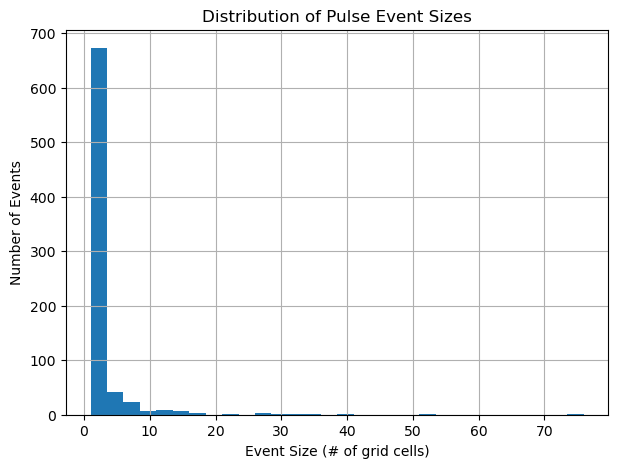

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.hist(event_summary["n_cells"], bins=30)

plt.xlabel("Event Size (# of grid cells)")
plt.ylabel("Number of Events")
plt.title("Distribution of Pulse Event Sizes")

plt.grid(True)
plt.show()

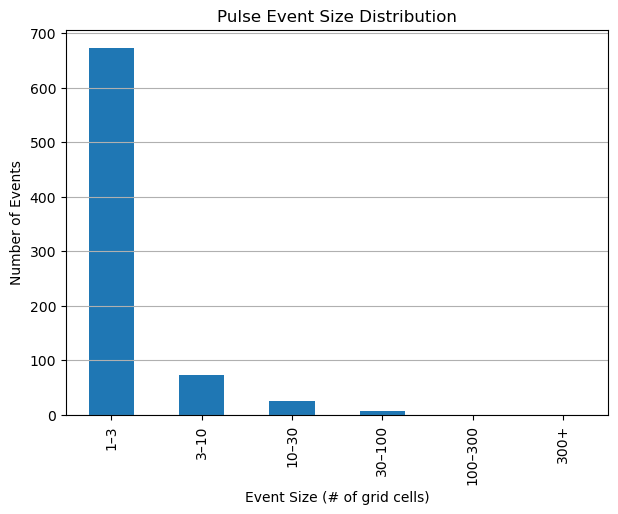

In [20]:
event_summary["size_bin"] = pd.cut(
    event_summary["n_cells"],
    bins=[0, 3, 10, 30, 100, 300, 1000],
    labels=["1–3", "3–10", "10–30", "30–100", "100–300", "300+"]
)

size_counts = (
    event_summary["size_bin"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7,5))

size_counts.plot(kind="bar")

plt.xlabel("Event Size (# of grid cells)")
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution")

plt.grid(axis="y")
plt.show()

In [21]:
event_summary.columns

Index(['group_id', 'n_cells', 'mean_no2', 'max_no2', 'std_no2', 'start_time',
       'start_hour_local', 'duration_hours', 'mean_precip', 'size_bin'],
      dtype='object')

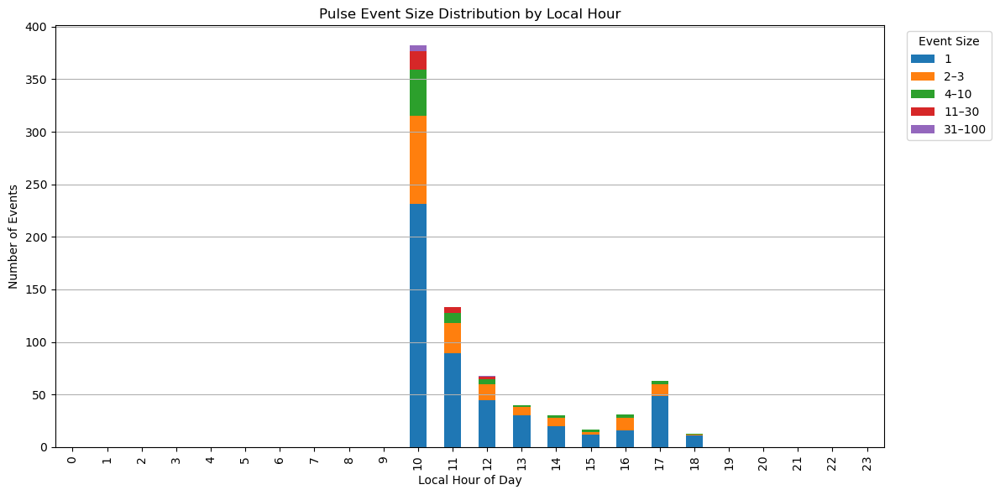

In [22]:
event_summary["size_bin"] = pd.cut(
    event_summary["n_cells"],
    bins=[0, 1, 3, 10, 30, 100, 300, np.inf],
    labels=["1", "2–3", "4–10", "11–30", "31–100", "101–300", "300+"],
    include_lowest=True
)

counts = (
    event_summary
    .groupby(["start_hour_local", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
)

# optional: force hours 0–23 to appear
counts = counts.reindex(range(24), fill_value=0)

counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.xlabel("Local Hour of Day")
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution by Local Hour")

plt.legend(title="Event Size", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

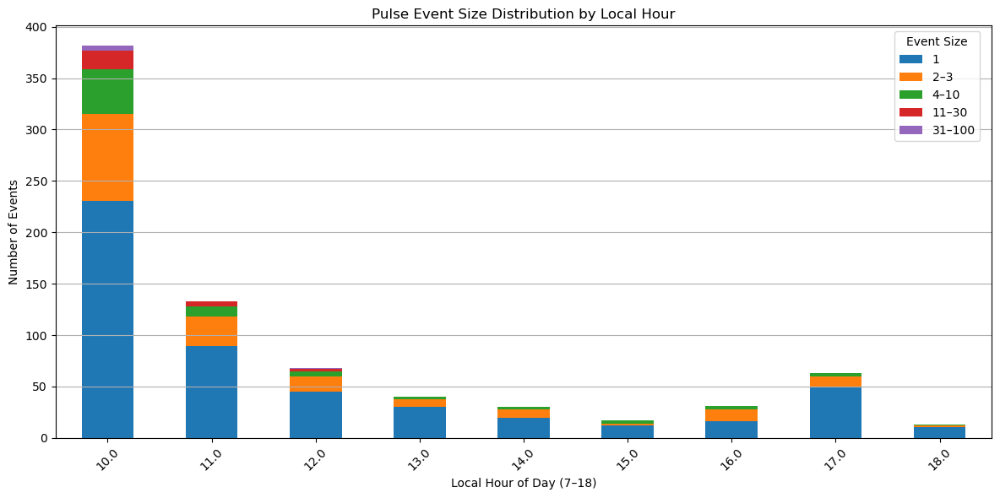

In [23]:
counts = (
    event_summary
    .groupby(["start_hour_local", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
)

# keep only 7–18
counts = counts.loc[7:18]

counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.xlabel("Local Hour of Day (7–18)")
plt.xticks(rotation=45)
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution by Local Hour")

plt.legend(title="Event Size", bbox_to_anchor=(0.89, 1), loc="upper left")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

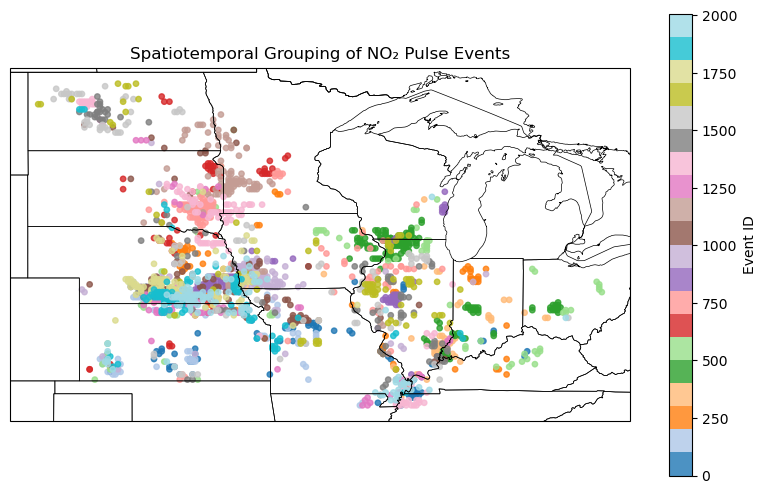

In [24]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

plot_df = pulse_df.copy()

fig = plt.figure(figsize=(10,6))
ax = plt.axes(projection=ccrs.PlateCarree())

# map features
ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.coastlines()

# scatter colored by group_id
sc = ax.scatter(
    plot_df["grid_lon"],
    plot_df["grid_lat"],
    c=plot_df["group_id"],
    cmap="tab20",
    s=15,
    alpha=0.8,
    transform=ccrs.PlateCarree()
)

plt.colorbar(sc, ax=ax, label="Event ID")

ax.set_title("Spatiotemporal Grouping of NO₂ Pulse Events")
plt.show()

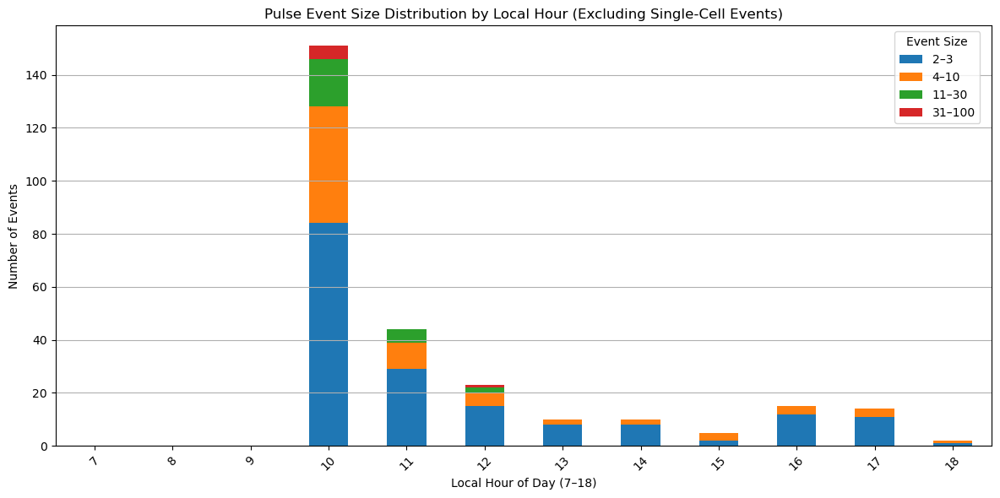

In [25]:
# remove single-cell events
event_summary_filtered = event_summary[event_summary["n_cells"] > 1]

counts = (
    event_summary_filtered[
        event_summary_filtered["start_hour_local"].between(7, 18)
    ]
    .groupby(["start_hour_local", "size_bin"], observed=True)
    .size()
    .unstack(fill_value=0)
)

# optional: ensure all hours 7–18 appear
counts = counts.reindex(range(7, 19), fill_value=0)

counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.xlabel("Local Hour of Day (7–18)")
plt.ylabel("Number of Events")
plt.title("Pulse Event Size Distribution by Local Hour (Excluding Single-Cell Events)")
plt.xticks(rotation=45)

plt.legend(title="Event Size", bbox_to_anchor=(0.89, 1), loc="upper left")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

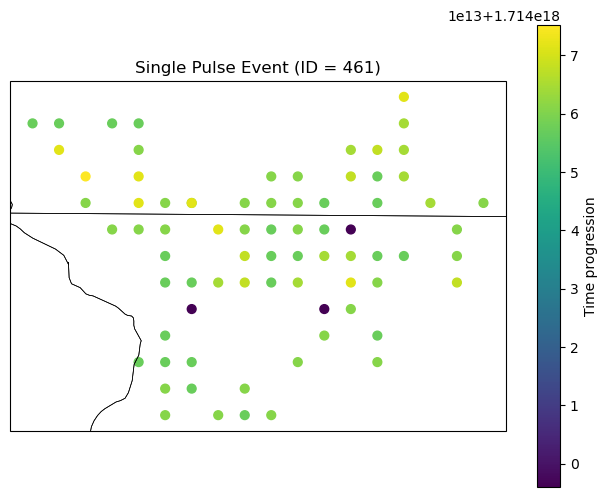

In [26]:
event_sizes = pulse_df["group_id"].value_counts()

big_group_id = event_sizes.index[0]  # largest event
event_df = pulse_df[pulse_df["group_id"] == big_group_id]

fig = plt.figure(figsize=(8,6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.coastlines()

sc = ax.scatter(
    event_df["grid_lon"],
    event_df["grid_lat"],
    c=event_df["datetime"].astype("int64"),  # color by time
    cmap="viridis",
    s=40,
    transform=ccrs.PlateCarree()
)

plt.colorbar(sc, ax=ax, label="Time progression")

ax.set_title(f"Single Pulse Event (ID = {big_group_id})")
plt.show()

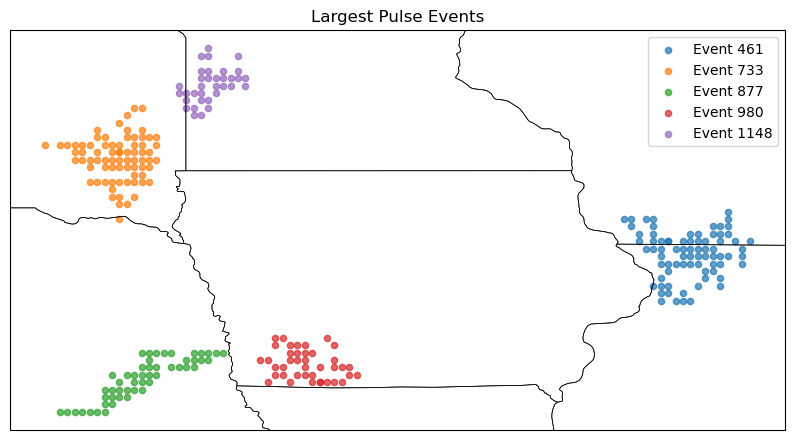

In [27]:
top_events = event_sizes.head(5).index

fig = plt.figure(figsize=(10,6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.coastlines()

for eid in top_events:
    sub = pulse_df[pulse_df["group_id"] == eid]
    
    ax.scatter(
        sub["grid_lon"],
        sub["grid_lat"],
        label=f"Event {eid}",
        s=20,
        alpha=0.7,
        transform=ccrs.PlateCarree()
    )

ax.legend()
ax.set_title("Largest Pulse Events")
plt.show()

In [28]:
# total individual pulse detections
n_pulses = len(pulse_df)

# total grouped events
n_events = pulse_df["group_id"].nunique()

print("Individual pulses:", n_pulses)
print("Grouped events:", n_events)

Individual pulses: 2009
Grouped events: 777


In [29]:
reduction_factor = n_pulses / n_events

print("Reduction factor:", reduction_factor)

Reduction factor: 2.5855855855855854


In [30]:
summary = {
    "Total individual pulses": n_pulses,
    "Total grouped events": n_events,
    "Mean event size": event_sizes.mean(),
    "Median event size": event_sizes.median(),
    "Max event size": event_sizes.max()
}

for k, v in summary.items():
    print(f"{k}: {v:.2f}")

Total individual pulses: 2009.00
Total grouped events: 777.00
Mean event size: 2.59
Median event size: 1.00
Max event size: 76.00


# are grouped events correlated with soil moisture changes?

In [31]:
pulse_df = pulse_df.dropna(subset=["sm_class"])#remove None

In [32]:
event_sm_counts = (
    pulse_df.groupby(["group_id", "sm_class"])
    .size()
    .unstack(fill_value=0)
)
event_sm_frac = event_sm_counts.div(event_sm_counts.sum(axis=1), axis=0)

In [33]:
THRESH = 0.7

# only keep numeric SM class columns
numeric_cols = event_sm_counts.columns  # e.g. ["Increasing", "Decreasing"]

event_sm_frac["dominant_class"] = event_sm_frac[numeric_cols].idxmax(axis=1)
event_sm_frac["dominant_frac"]  = event_sm_frac[numeric_cols].max(axis=1)

event_sm_frac["coherent"] = event_sm_frac["dominant_frac"] >= THRESH

In [34]:
n_events = len(event_sm_frac)
n_coherent = event_sm_frac["coherent"].sum()

print("Total events:", n_events)
print("Coherent events:", n_coherent)
print("Fraction coherent:", n_coherent / n_events)

Total events: 777
Coherent events: 759
Fraction coherent: 0.9768339768339769


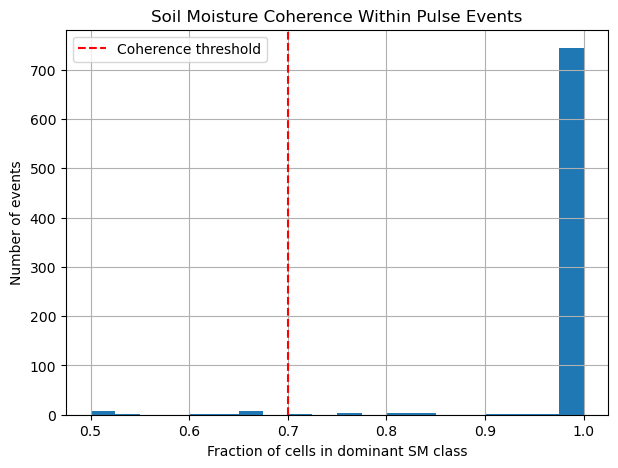

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.hist(event_sm_frac["dominant_frac"], bins=20)

plt.xlabel("Fraction of cells in dominant SM class")
plt.ylabel("Number of events")
plt.title("Soil Moisture Coherence Within Pulse Events")

plt.axvline(0.7, color="red", linestyle="--", label="Coherence threshold")
plt.legend()

plt.grid(True)
plt.show()

In [36]:
coherent_events = event_sm_frac[event_sm_frac["coherent"]]

print(coherent_events["dominant_class"].value_counts())

dominant_class
decreasing    482
increasing    277
Name: count, dtype: int64


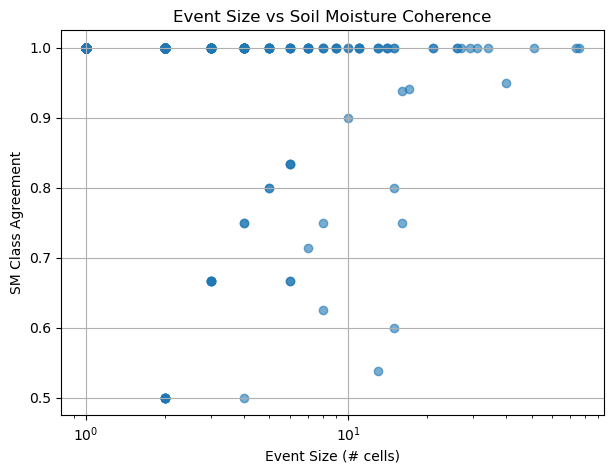

In [37]:
event_sizes = pulse_df.groupby("group_id").size()

plot_df = event_sm_frac.copy()
plot_df["event_size"] = event_sizes

plt.figure(figsize=(7,5))

plt.scatter(
    plot_df["event_size"],
    plot_df["dominant_frac"],
    alpha=0.6
)

plt.xscale("log")

plt.xlabel("Event Size (# cells)")
plt.ylabel("SM Class Agreement")
plt.title("Event Size vs Soil Moisture Coherence")

plt.grid(True)
plt.show()

In [38]:
event_sizes = pulse_df.groupby("group_id").size().rename("event_size")

plot_df = event_sm_frac.copy()
plot_df = plot_df.merge(event_sizes, left_index=True, right_index=True)

import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

for sm_class, color in zip(["Increasing", "Decreasing"], ["blue", "red"]):
    sub = plot_df[plot_df["dominant_class"] == sm_class]
    
    plt.scatter(
        sub["event_size"],
        sub["dominant_frac"],
        label=sm_class,
        alpha=0.6,
        color=color
    )

plt.xscale("log")

plt.xlabel("Event Size (# grid cells)")
plt.ylabel("SM Class Agreement")
plt.title("Event Size vs Soil Moisture Regime")

plt.legend()
plt.grid(True)
plt.show()

ValueError: Data has no positive values, and therefore cannot be log-scaled.

<Figure size 700x500 with 1 Axes>

/tmp/ipykernel_1222785/1393992539.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df.groupby(["size_bin", "dominant_class"])


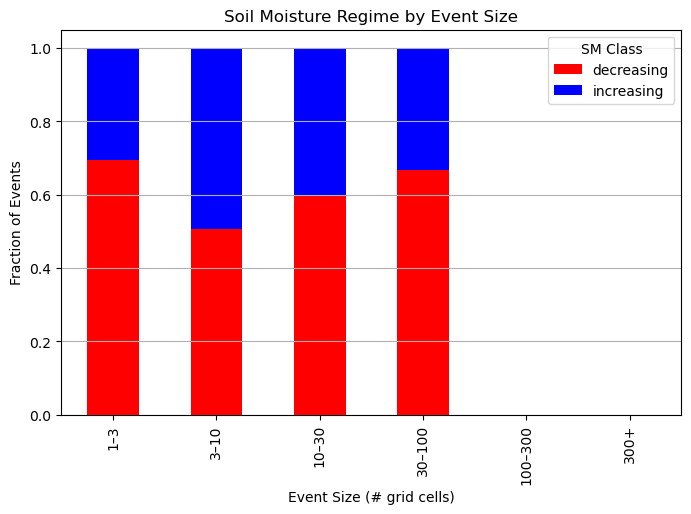

In [39]:
plot_df["size_bin"] = pd.cut(
    plot_df["event_size"],
    bins=[1, 3, 10, 30, 100, 300, 1000],
    labels=["1–3", "3–10", "10–30", "30–100", "100–300", "300+"]
)
size_sm_counts = (
    plot_df.groupby(["size_bin", "dominant_class"])
    .size()
    .unstack(fill_value=0)
)
size_sm_frac = size_sm_counts.div(size_sm_counts.sum(axis=1), axis=0)

size_sm_frac.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5),
    color=["red", "blue"]  # Decreasing, Increasing
)

plt.xlabel("Event Size (# grid cells)")
plt.ylabel("Fraction of Events")
plt.title("Soil Moisture Regime by Event Size")

plt.legend(title="SM Class")
plt.grid(axis="y")
plt.show()

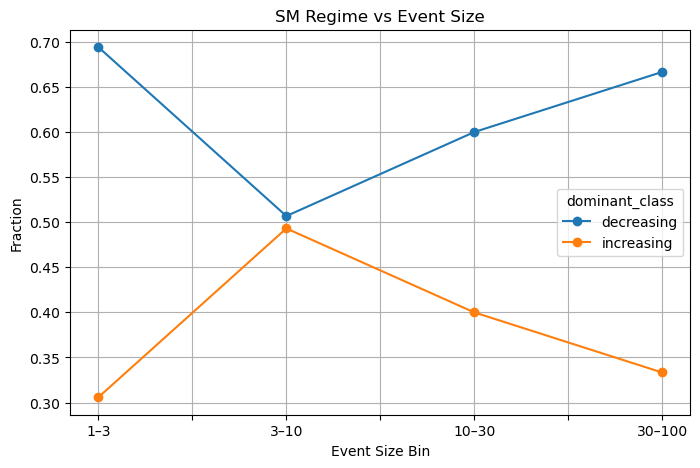

In [40]:
size_sm_frac.plot(
    marker="o",
    figsize=(8,5)
)

plt.xlabel("Event Size Bin")
plt.ylabel("Fraction")
plt.title("SM Regime vs Event Size")

plt.grid(True)
plt.show()

# old code 

In [36]:
# -------------------------------------------------
# 1. Largest grouped events
# -------------------------------------------------
event_sizes = pulse_df.groupby("group_id").size().sort_values(ascending=False)
top_events = event_sizes.head(5).index

# make sure datetime is datetime
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])
pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

records = []

WINDOW_DAYS = 7

for eid in top_events:
    # ---------------------------------------------
    # 2. cells in this grouped event
    # ---------------------------------------------
    event_cells = (
        pulse_df.loc[pulse_df["group_id"] == eid, ["grid_lat", "grid_lon"]]
        .drop_duplicates()
    )

    # ---------------------------------------------
    # 3. representative event time
    #    use earliest pulse in the grouped event
    # ---------------------------------------------
    t0 = pulse_df.loc[pulse_df["group_id"] == eid, "datetime"].min()

    # ---------------------------------------------
    # 4. pull full time series for these cells
    # ---------------------------------------------
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()

    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    # lag in days
    sub["lag_days"] = (sub["datetime"] - t0).dt.total_seconds() / 86400.0

    # optional: round to nearest day for daily composites
    sub["lag_day"] = sub["lag_days"].round().astype(int)

    # ---------------------------------------------
    # 5. average over all cells in the event by lag day
    # ---------------------------------------------
    daily = (
        sub.groupby("lag_day")
        .agg(
            soil_temp_layer1=("soil_temp_layer1", "mean"),
            h_precip_mm=("h_precip_mm", "sum"),
            sm_surface=("sm_surface", "mean"),
            no2_mean=("no2_mean", "mean")
        )
        .reset_index()
    )

    daily["group_id"] = eid
    records.append(daily)

plot_df = pd.concat(records, ignore_index=True)

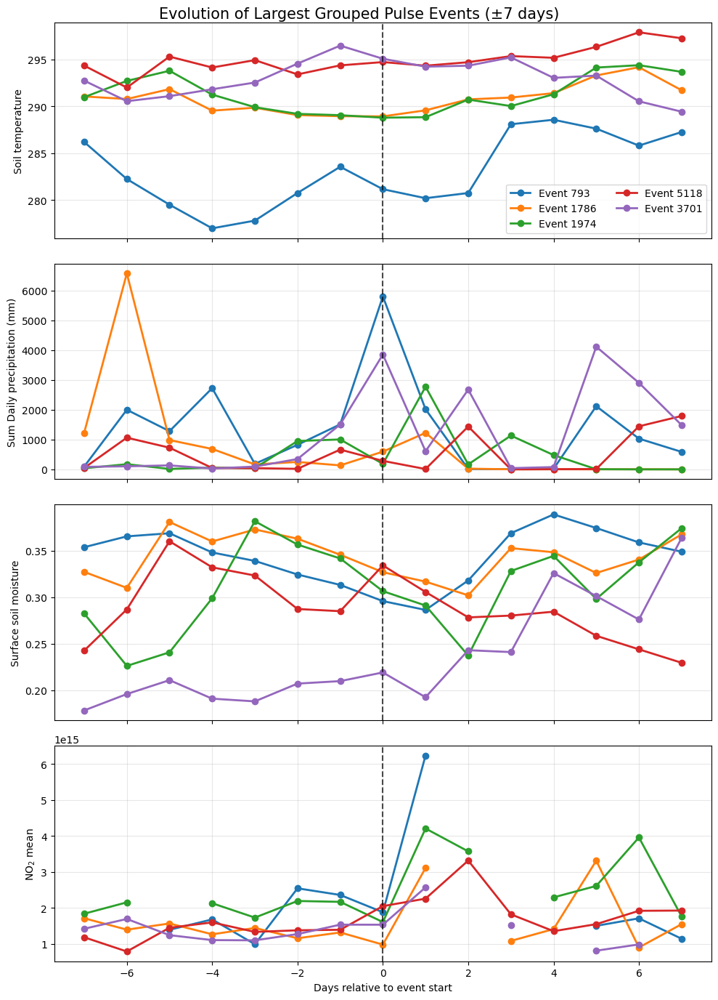

In [37]:
fig, axes = plt.subplots(4, 1, figsize=(10, 14), sharex=True)

vars_to_plot = [
    ("soil_temp_layer1", "Soil temperature"),
    ("h_precip_mm", "Sum Daily precipitation (mm)"),
    ("sm_surface", "Surface soil moisture"),
    ("no2_mean", "NO$_2$ mean")
]

for ax, (var, ylabel) in zip(axes, vars_to_plot):
    for eid in top_events:
        sub = plot_df[plot_df["group_id"] == eid]

        ax.plot(
            sub["lag_day"],
            sub[var],
            marker="o",
            linewidth=2,
            label=f"Event {eid}"
        )

    ax.axvline(0, color="k", linestyle="--", alpha=0.7)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

axes[0].legend(loc="best", ncol=2)
axes[-1].set_xlabel("Days relative to event start")

fig.suptitle("Evolution of Largest Grouped Pulse Events (±7 days)", fontsize=15)
plt.tight_layout()
plt.show()

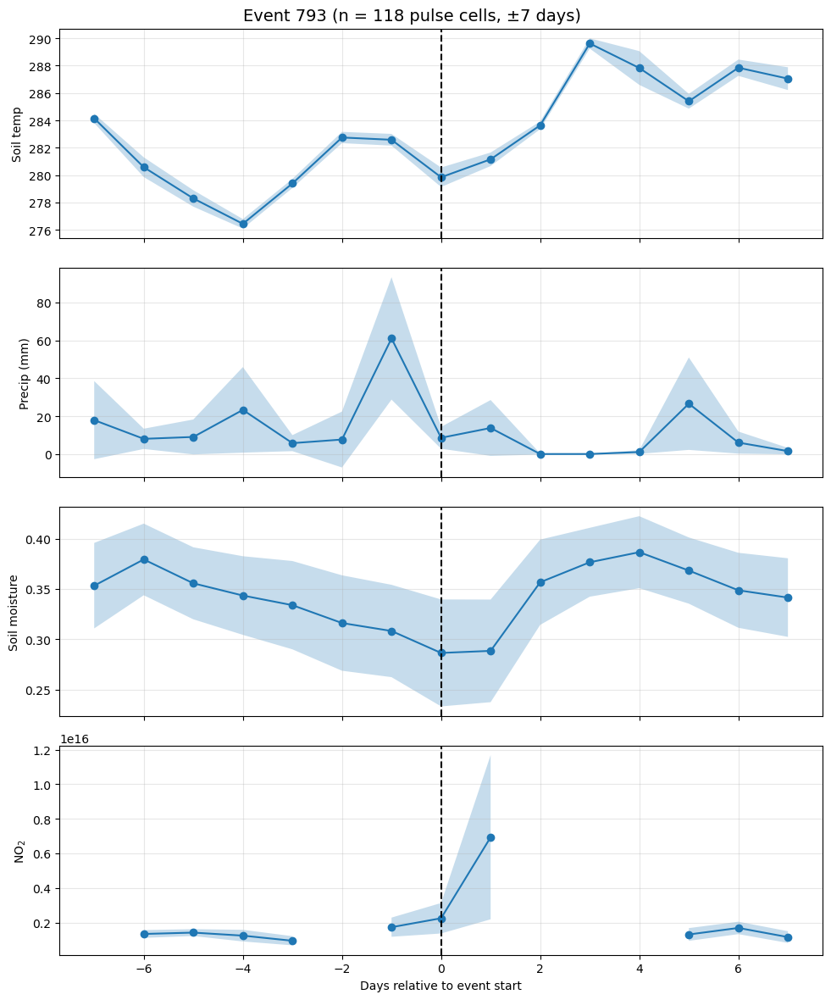

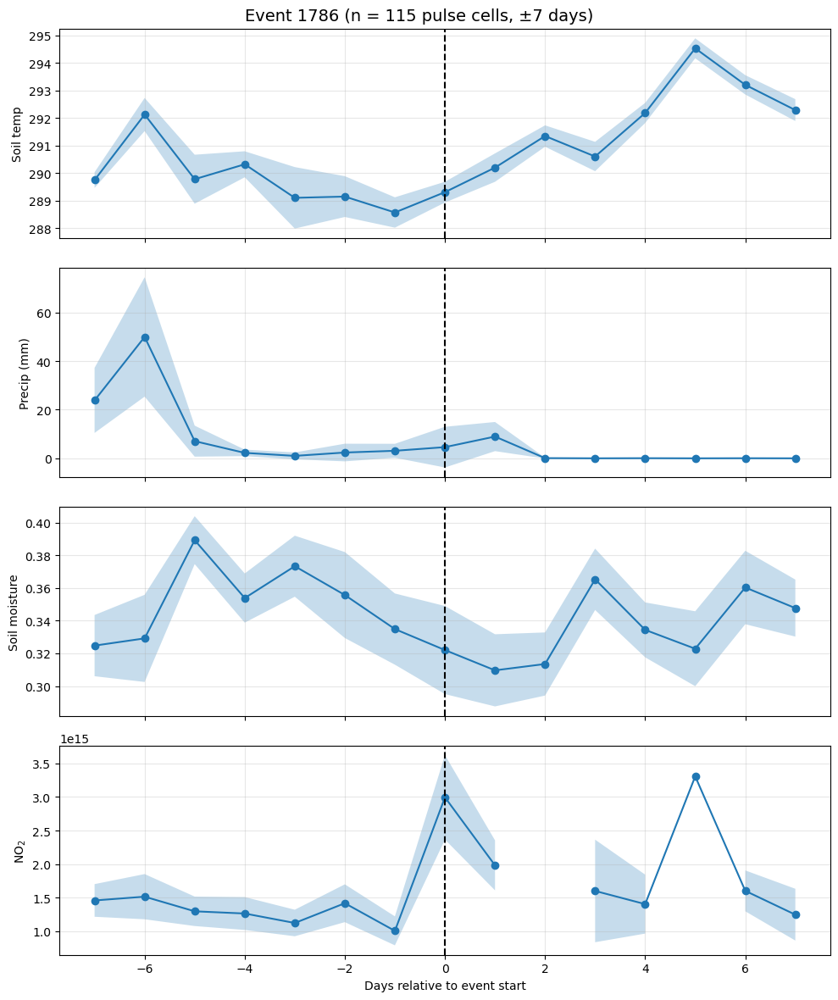

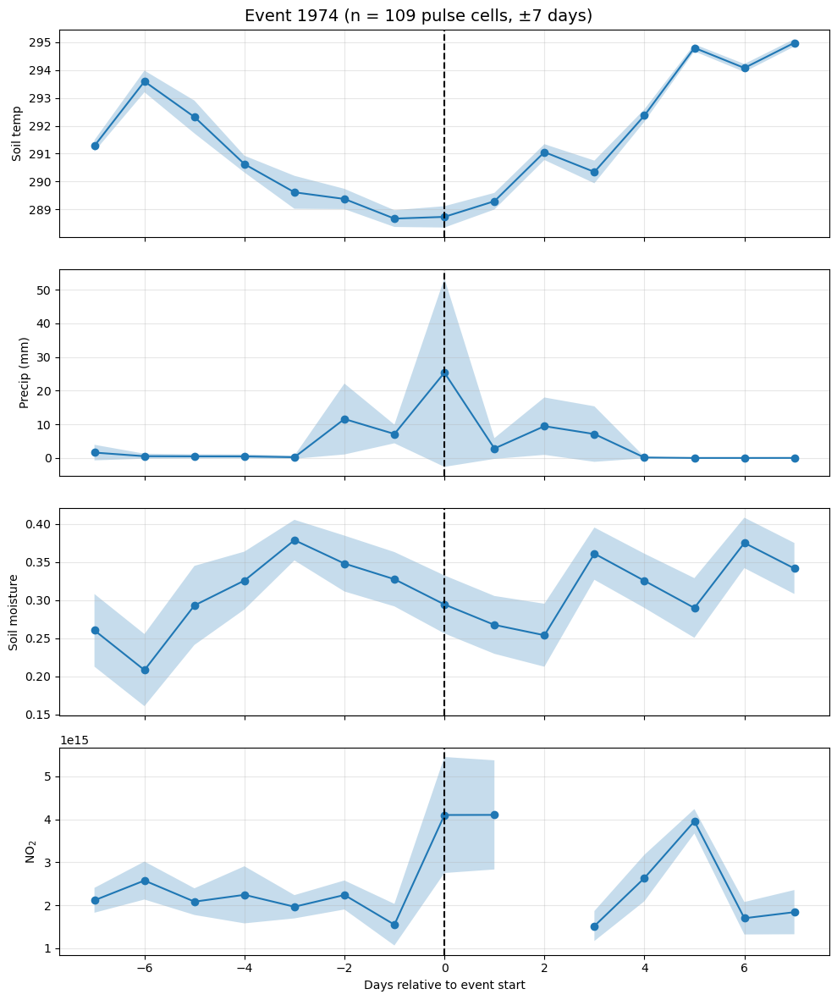

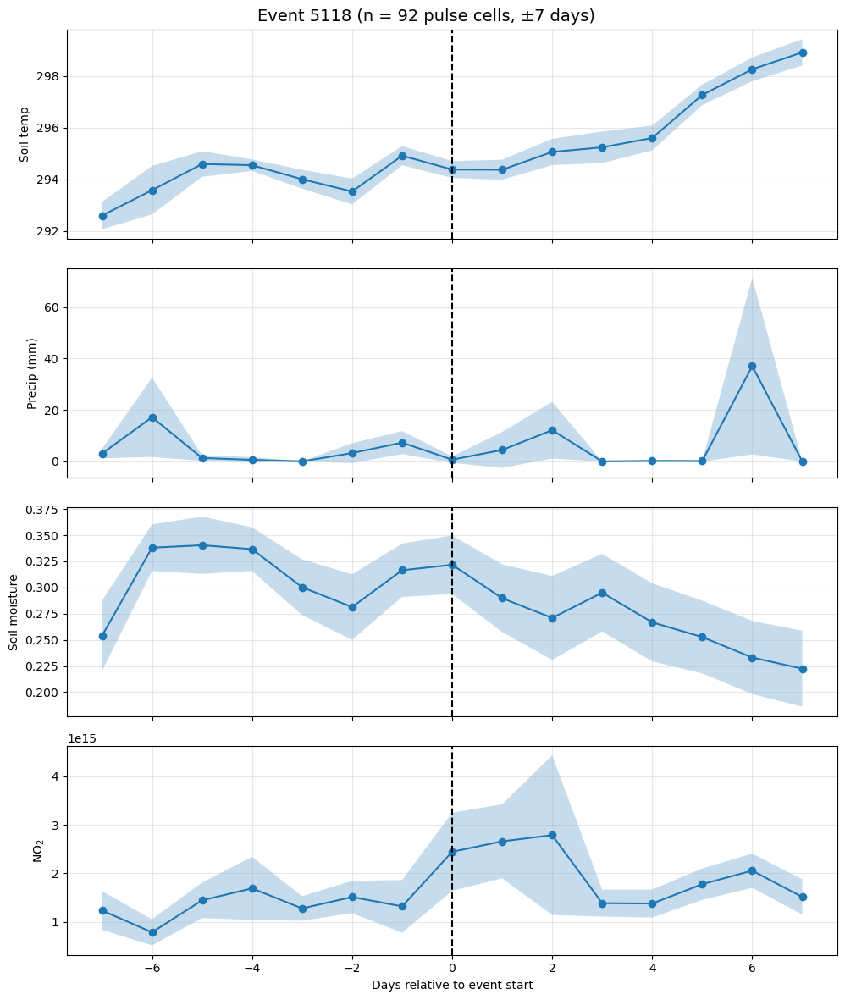

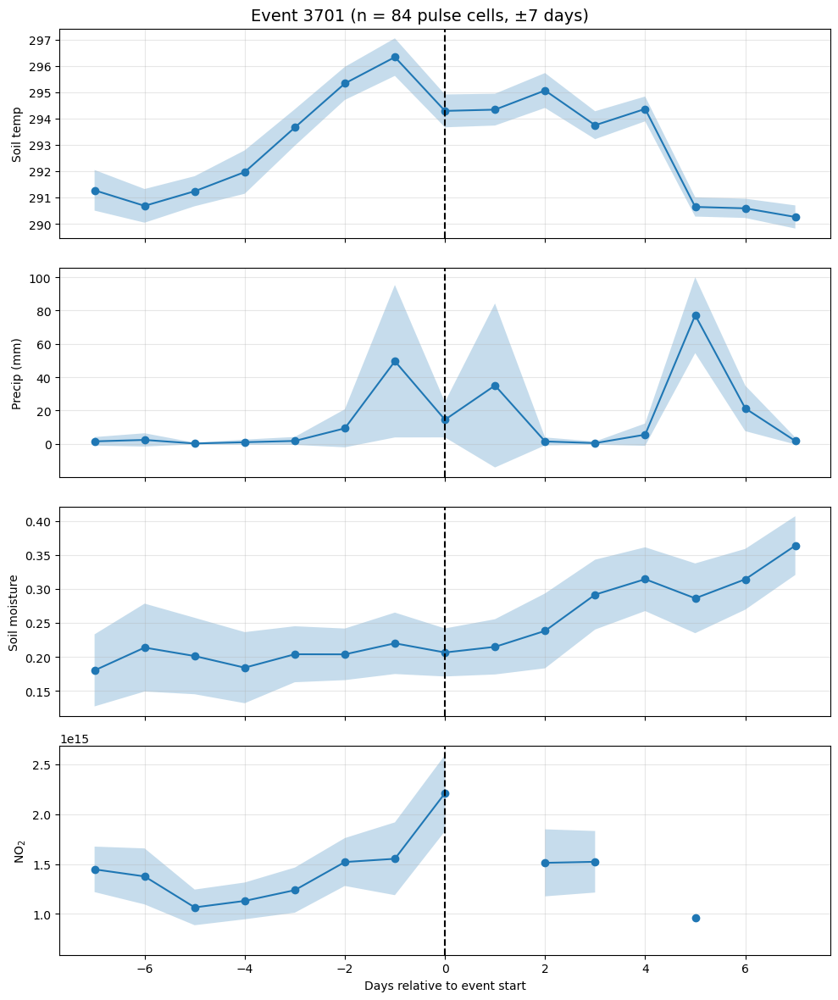

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------
# 1. Find largest grouped events
# -------------------------------------------------
event_sizes = pulse_df.groupby("group_id").size().sort_values(ascending=False)
top_events = event_sizes.head(5).index

# make sure datetime columns are datetime
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])

pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

WINDOW_DAYS = 7

# -------------------------------------------------
# 2. Loop through each event and make its own figure
# -------------------------------------------------
for eid in top_events:

    # unique cells in this event
    event_cells = (
        pulse_df.loc[pulse_df["group_id"] == eid, ["grid_lat", "grid_lon"]]
        .drop_duplicates()
    )

    # representative event time = first pulse time in the grouped event
    t0 = pulse_df.loc[pulse_df["group_id"] == eid, "datetime"].min()

    # full time series for all event cells from original df
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()

    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    # lag in days
    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    # ---------------------------------------------
    # Average within each cell-day first
    # ---------------------------------------------
    cell_daily = (
        sub.groupby(["grid_lat", "grid_lon", "lag_day"])
        .agg(
            soil_temp_layer1=("soil_temp_layer1", "mean"),
            h_precip_mm=("h_precip_mm", "sum"),
            sm_surface=("sm_surface", "mean"),
            no2_mean=("no2_mean", "mean")
        )
        .reset_index()
    )

    # ---------------------------------------------
    # Then average across event cells
    # ---------------------------------------------
    event_daily = (
        cell_daily.groupby("lag_day")
        .agg(
            soil_temp_mean=("soil_temp_layer1", "mean"),
            soil_temp_std=("soil_temp_layer1", "std"),
            precip_mean=("h_precip_mm", "mean"),
            precip_std=("h_precip_mm", "std"),
            sm_mean=("sm_surface", "mean"),
            sm_std=("sm_surface", "std"),
            no2_mean=("no2_mean", "mean"),
            no2_std=("no2_mean", "std")
        )
        .reset_index()
    )

    # optional: force full lag range to appear
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")

    # ---------------------------------------------
    # Plot 4 panels for this event
    # ---------------------------------------------
    fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

    # 1. Soil temperature
    axes[0].plot(event_daily["lag_day"], event_daily["soil_temp_mean"], marker="o")
    axes[0].fill_between(
        event_daily["lag_day"],
        event_daily["soil_temp_mean"] - event_daily["soil_temp_std"],
        event_daily["soil_temp_mean"] + event_daily["soil_temp_std"],
        alpha=0.25
    )
    axes[0].axvline(0, color="k", linestyle="--")
    axes[0].set_ylabel("Soil temp")
    axes[0].grid(True, alpha=0.3)

    # 2. Precipitation
    axes[1].plot(event_daily["lag_day"], event_daily["precip_mean"], marker="o")
    axes[1].fill_between(
        event_daily["lag_day"],
        event_daily["precip_mean"] - event_daily["precip_std"],
        event_daily["precip_mean"] + event_daily["precip_std"],
        alpha=0.25
    )
    axes[1].axvline(0, color="k", linestyle="--")
    axes[1].set_ylabel("Precip (mm)")
    axes[1].grid(True, alpha=0.3)

    # 3. Soil moisture
    axes[2].plot(event_daily["lag_day"], event_daily["sm_mean"], marker="o")
    axes[2].fill_between(
        event_daily["lag_day"],
        event_daily["sm_mean"] - event_daily["sm_std"],
        event_daily["sm_mean"] + event_daily["sm_std"],
        alpha=0.25
    )
    axes[2].axvline(0, color="k", linestyle="--")
    axes[2].set_ylabel("Soil moisture")
    axes[2].grid(True, alpha=0.3)

    # 4. NO2
    axes[3].plot(event_daily["lag_day"], event_daily["no2_mean"], marker="o")
    axes[3].fill_between(
        event_daily["lag_day"],
        event_daily["no2_mean"] - event_daily["no2_std"],
        event_daily["no2_mean"] + event_daily["no2_std"],
        alpha=0.25
    )
    axes[3].axvline(0, color="k", linestyle="--")
    axes[3].set_ylabel("NO$_2$")
    axes[3].set_xlabel("Days relative to event start")
    axes[3].grid(True, alpha=0.3)

    n_cells = event_sizes.loc[eid]
    fig.suptitle(f"Event {eid} (n = {n_cells} pulse cells, ±{WINDOW_DAYS} days)", fontsize=14)

    plt.tight_layout()
    plt.show()

/tmp/ipykernel_112902/2616965522.py:213: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.985])


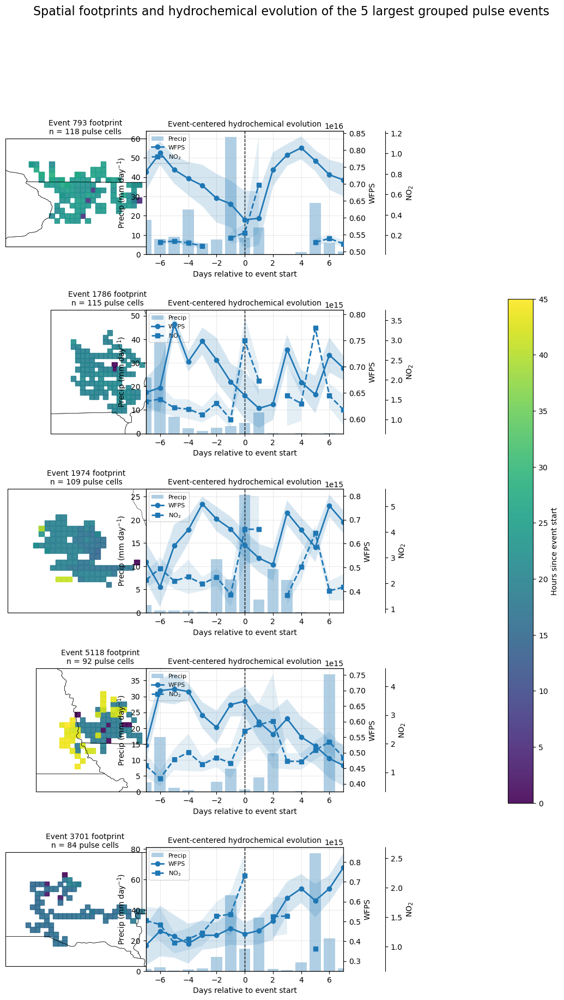

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# -------------------------------------------------
# 1. Choose largest grouped events
# -------------------------------------------------
event_sizes = pulse_df.groupby("group_id").size().sort_values(ascending=False)
top_events = event_sizes.head(5).index   # change to head(4) if you want 4

df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])

pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

WINDOW_DAYS = 7

# -------------------------------------------------
# 2. Figure layout
# -------------------------------------------------
n_events = len(top_events)

fig = plt.figure(figsize=(14, 4 * n_events))
gs = gridspec.GridSpec(
    n_events, 2,
    width_ratios=[1.0, 1.8],
    hspace=0.45,
    wspace=0.2
)

# global color scale for footprint timing
all_hours = (
    (pulse_df.loc[pulse_df["group_id"].isin(top_events), "datetime"] -
     pulse_df.loc[pulse_df["group_id"].isin(top_events)].groupby("group_id")["datetime"].transform("min"))
    .dt.total_seconds() / 3600
)

vmin_time = 0
vmax_time = all_hours.max()

for row, eid in enumerate(top_events):

    # -------------------------------------------------
    # 3. Get event cells and event timing
    # -------------------------------------------------
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()

    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    t0 = event_pulses["datetime"].min()

    # time since event start for coloring footprint
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # -------------------------------------------------
    # 4. Pull full time series for those cells
    # -------------------------------------------------
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()

    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    # average within each cell-day first
    cell_daily = (
        sub.groupby(["grid_lat", "grid_lon", "lag_day"])
        .agg(
            precip=("h_precip_mm", "sum"),
            wfps=("WFPS_c", "mean"),
            no2=("no2_mean", "mean")
        )
        .reset_index()
    )

    # then average across cells in the event
    event_daily = (
        cell_daily.groupby("lag_day")
        .agg(
            precip_mean=("precip", "mean"),
            precip_std=("precip", "std"),
            wfps_mean=("wfps", "mean"),
            wfps_std=("wfps", "std"),
            no2_mean=("no2", "mean"),
            no2_std=("no2", "std")
        )
        .reset_index()
    )

    # force full lag range
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")

    # -------------------------------------------------
    # 5. Left panel: footprint map
    # -------------------------------------------------
    ax_map = fig.add_subplot(gs[row, 0], projection=ccrs.PlateCarree())

    # zoom around event
    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5
    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)

    sc = ax_map.scatter(
        event_pulses["grid_lon"],
        event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"],
        cmap="viridis",
        vmin=vmin_time,
        vmax=vmax_time,
        s=45,
        marker="s",
        alpha=0.9,
        transform=ccrs.PlateCarree()
    )

    ax_map.set_title(f"Event {eid} footprint\nn = {event_sizes.loc[eid]} pulse cells", fontsize=10)

    # -------------------------------------------------
    # 6. Right panel: time series with 3 axes
    # -------------------------------------------------
    ax_ts = fig.add_subplot(gs[row, 1])

    # left axis: precip
    ax_ts.bar(
        event_daily["lag_day"],
        event_daily["precip_mean"],
        alpha=0.35,
        width=0.8,
        label="Precip"
    )
    ax_ts.set_ylabel("Precip (mm day$^{-1}$)")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1)
    ax_ts.grid(True, alpha=0.25)

    # first right axis: WFPS
    ax_wfps = ax_ts.twinx()
    ax_wfps.plot(
        event_daily["lag_day"],
        event_daily["wfps_mean"],
        marker="o",
        linewidth=2,
        label="WFPS"
    )
    ax_wfps.fill_between(
        event_daily["lag_day"],
        event_daily["wfps_mean"] - event_daily["wfps_std"],
        event_daily["wfps_mean"] + event_daily["wfps_std"],
        alpha=0.18
    )
    ax_wfps.set_ylabel("WFPS")

    # second right axis: NO2
    ax_no2 = ax_ts.twinx()
    ax_no2.spines["right"].set_position(("outward", 55))
    ax_no2.plot(
        event_daily["lag_day"],
        event_daily["no2_mean"],
        marker="s",
        linestyle="--",
        linewidth=2,
        label="NO$_2$"
    )
    ax_no2.fill_between(
        event_daily["lag_day"],
        event_daily["no2_mean"] - event_daily["no2_std"],
        event_daily["no2_mean"] + event_daily["no2_std"],
        alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xlabel("Days relative to event start")
    ax_ts.set_title("Event-centered hydrochemical evolution", fontsize=10)

    # combine legends
    handles1, labels1 = ax_ts.get_legend_handles_labels()
    handles2, labels2 = ax_wfps.get_legend_handles_labels()
    handles3, labels3 = ax_no2.get_legend_handles_labels()
    ax_ts.legend(
        handles1 + handles2 + handles3,
        labels1 + labels2 + labels3,
        loc="upper left",
        fontsize=8
    )

# shared colorbar for maps
cbar = fig.colorbar(sc, ax=fig.axes, shrink=0.6, pad=0.02)
cbar.set_label("Hours since event start")

fig.suptitle(
    f"Spatial footprints and hydrochemical evolution of the {n_events} largest grouped pulse events",
    fontsize=16,
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

/tmp/ipykernel_112902/172014867.py:256: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.03, 0.06, 0.98, 0.96])


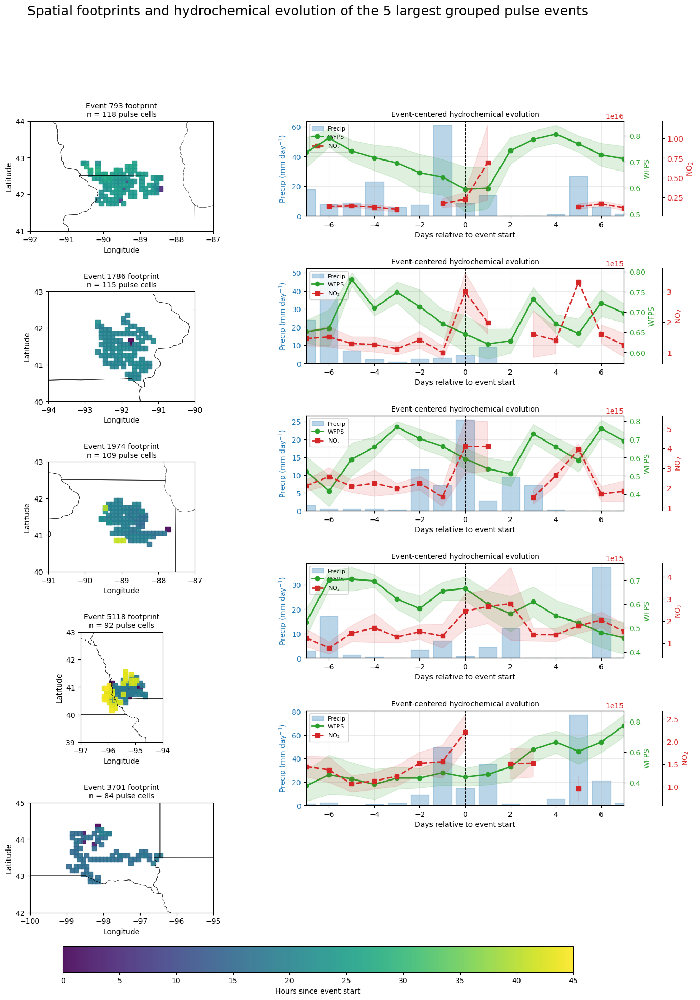

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# -------------------------------------------------
# 1. Choose largest grouped events
# -------------------------------------------------
event_sizes = pulse_df.groupby("group_id").size().sort_values(ascending=False)
top_events = event_sizes.head(5).index   # change to head(4) if you want 4

df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])

pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

WINDOW_DAYS = 7

# -------------------------------------------------
# 2. Figure layout
# -------------------------------------------------
n_events = len(top_events)

fig = plt.figure(figsize=(15, 4.2 * n_events))

# more room between left/right panels, and on the right for colorbar
gs = gridspec.GridSpec(
    n_events, 2,
    width_ratios=[1.0, 1.45],
    hspace=0.55,
    wspace=0.28
)

# -------------------------------------------------
# 3. Global color scale for footprint timing
# -------------------------------------------------
all_hours = (
    (
        pulse_df.loc[pulse_df["group_id"].isin(top_events), "datetime"]
        - pulse_df.loc[pulse_df["group_id"].isin(top_events)]
          .groupby("group_id")["datetime"].transform("min")
    )
    .dt.total_seconds() / 3600
)

vmin_time = 0
vmax_time = all_hours.max()

last_sc = None  # for shared colorbar

for row, eid in enumerate(top_events):

    # -------------------------------------------------
    # 4. Get event cells and event timing
    # -------------------------------------------------
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    t0 = event_pulses["datetime"].min()

    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # -------------------------------------------------
    # 5. Pull full time series for those cells
    # -------------------------------------------------
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()

    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    # average within each cell-day first
    cell_daily = (
        sub.groupby(["grid_lat", "grid_lon", "lag_day"])
        .agg(
            precip=("h_precip_mm", "sum"),
            wfps=("WFPS_c", "mean"),
            no2=("no2_mean", "mean")
        )
        .reset_index()
    )

    # then average across cells in the event
    event_daily = (
        cell_daily.groupby("lag_day")
        .agg(
            precip_mean=("precip", "mean"),
            precip_std=("precip", "std"),
            wfps_mean=("wfps", "mean"),
            wfps_std=("wfps", "std"),
            no2_mean=("no2", "mean"),
            no2_std=("no2", "std")
        )
        .reset_index()
    )

    # full lag range
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    # fill ONLY precip (and maybe WFPS if you want), NOT NO2
    event_daily["precip_mean"] = event_daily["precip_mean"].fillna(0)
    event_daily["precip_std"] = event_daily["precip_std"].fillna(0)

# leave NO2 as NaN so line connects across gaps
# (same for wfps if you want gaps there too)
    # -------------------------------------------------
    # 6. Left panel: footprint map
    # -------------------------------------------------
    ax_map = fig.add_subplot(gs[row, 0], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5
    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)

    # add lat/lon ticks and labels
    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 0.1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 0.1, 1)
    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")

    sc = ax_map.scatter(
        event_pulses["grid_lon"],
        event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"],
        cmap="viridis",
        vmin=vmin_time,
        vmax=vmax_time,
        s=42,
        marker="s",
        alpha=0.9,
        transform=ccrs.PlateCarree()
    )
    last_sc = sc

    ax_map.set_title(
        f"Event {eid} footprint\nn = {event_sizes.loc[eid]} pulse cells",
        fontsize=10
    )

    # -------------------------------------------------
    # 7. Right panel: time series with 3 axes
    # -------------------------------------------------
    ax_ts = fig.add_subplot(gs[row, 1])

    # left axis: precip in blue
    ax_ts.bar(
        event_daily["lag_day"],
        event_daily["precip_mean"],
        alpha=0.30,
        width=0.8,
        color="tab:blue",
        edgecolor="tab:blue",
        label="Precip"
    )
    ax_ts.set_ylabel("Precip (mm day$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1)
    ax_ts.grid(True, alpha=0.25)

    # first right axis: WFPS in green
    ax_wfps = ax_ts.twinx()
    ax_wfps.plot(
        event_daily["lag_day"],
        event_daily["wfps_mean"],
        marker="o",
        linewidth=2,
        color="tab:green",
        label="WFPS"
    )
    ax_wfps.fill_between(
        event_daily["lag_day"],
        event_daily["wfps_mean"] - event_daily["wfps_std"],
        event_daily["wfps_mean"] + event_daily["wfps_std"],
        color="tab:green",
        alpha=0.15
    )
    ax_wfps.set_ylabel("WFPS", color="tab:green")
    ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    # second right axis: NO2 in red
    ax_no2 = ax_ts.twinx()
    ax_no2.spines["right"].set_position(("outward", 52))
    ax_no2.plot(
        event_daily["lag_day"],
        event_daily["no2_mean"],
        marker="s",
        linestyle="--",
        linewidth=2,
        color="tab:red",
        label="NO$_2$"
    )
    ax_no2.fill_between(
        event_daily["lag_day"],
        event_daily["no2_mean"] - event_daily["no2_std"],
        event_daily["no2_mean"] + event_daily["no2_std"],
        color="tab:red",
        alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xlabel("Days relative to event start")
    ax_ts.set_title("Event-centered hydrochemical evolution", fontsize=10)

    # combined legend
    handles1, labels1 = ax_ts.get_legend_handles_labels()
    handles2, labels2 = ax_wfps.get_legend_handles_labels()
    handles3, labels3 = ax_no2.get_legend_handles_labels()
    ax_ts.legend(
        handles1 + handles2 + handles3,
        labels1 + labels2 + labels3,
        loc="upper left",
        fontsize=8,
        frameon=True
    )

# -------------------------------------------------
# 8. Shared colorbar in its own axis
# -------------------------------------------------
cbar = fig.colorbar(
    last_sc,
    ax=fig.axes,
    orientation="horizontal",
    fraction=0.03,
    pad=0.04
)

cbar.set_label("Hours since event start")

# -------------------------------------------------
# 9. Title and final layout
# -------------------------------------------------
fig.suptitle(
    f"Spatial footprints and hydrochemical evolution of the {n_events} largest grouped pulse events",
    fontsize=18,
    y=0.985
)
plt.tight_layout(rect=[0.03, 0.06, 0.98, 0.96])
plt.show()

/tmp/ipykernel_265453/1549999128.py:244: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.03, 0.03, 0.98, 0.975])


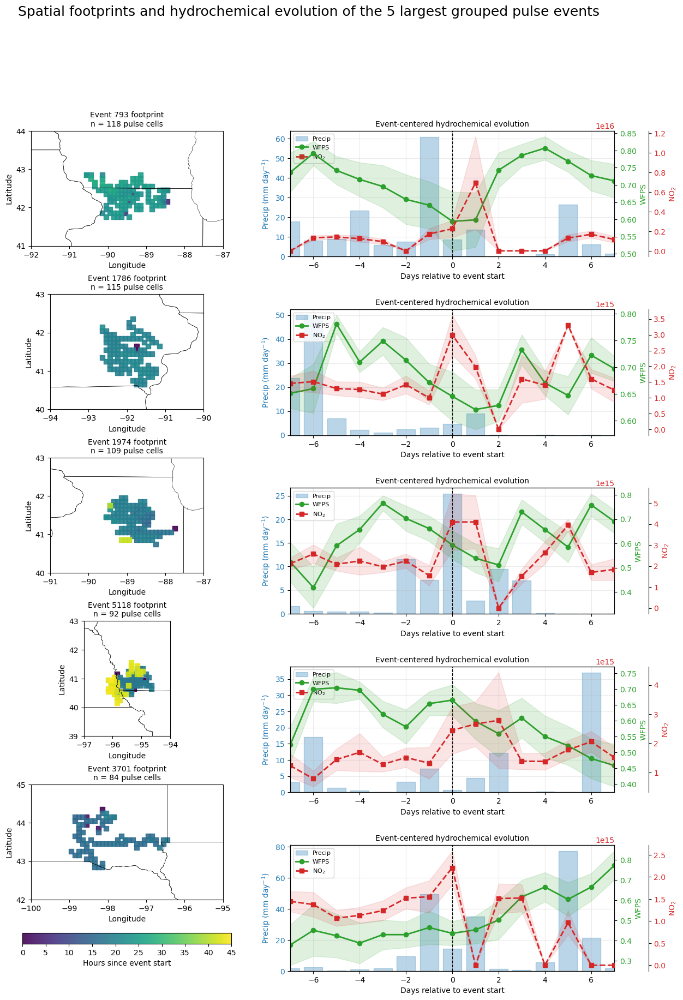

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# -------------------------------------------------
# 1. Choose largest grouped events
# -------------------------------------------------
event_sizes = pulse_df.groupby("group_id").size().sort_values(ascending=False)
top_events = event_sizes.head(5).index

df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])

pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

WINDOW_DAYS = 7
n_events = len(top_events)

# -------------------------------------------------
# 2. Figure + outer layout
# -------------------------------------------------
fig = plt.figure(figsize=(14, 4.0 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.42)

map_axes = []
ts_axes = []
last_sc = None

# global color scale for map timing
all_hours = (
    (
        pulse_df.loc[pulse_df["group_id"].isin(top_events), "datetime"]
        - pulse_df.loc[pulse_df["group_id"].isin(top_events)]
          .groupby("group_id")["datetime"].transform("min")
    )
    .dt.total_seconds() / 3600
)

vmin_time = 0
vmax_time = all_hours.max()

for row, eid in enumerate(top_events):

    # one row = map + time series
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2,
        subplot_spec=outer[row],
        width_ratios=[1.0, 1.55],
        wspace=0.22
    )

    # -------------------------------------------------
    # Event data
    # -------------------------------------------------
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    t0 = event_pulses["datetime"].min()

    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    cell_daily = (
        sub.groupby(["grid_lat", "grid_lon", "lag_day"])
        .agg(
            precip=("h_precip_mm", "sum"),
            wfps=("WFPS_c", "mean"),
            no2=("no2_mean", "mean")
        )
        .reset_index()
    )

    event_daily = (
        cell_daily.groupby("lag_day")
        .agg(
            precip_mean=("precip", "mean"),
            precip_std=("precip", "std"),
            wfps_mean=("wfps", "mean"),
            wfps_std=("wfps", "std"),
            no2_mean=("no2", "mean"),
            no2_std=("no2", "std")
        )
        .reset_index()
    )

    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left").fillna(0)

    # -------------------------------------------------
    # Left panel: map
    # -------------------------------------------------
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)

    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5
    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 0.1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 0.1, 1)
    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")

    sc = ax_map.scatter(
        event_pulses["grid_lon"],
        event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"],
        cmap="viridis",
        vmin=vmin_time,
        vmax=vmax_time,
        s=42,
        marker="s",
        alpha=0.9,
        transform=ccrs.PlateCarree()
    )
    last_sc = sc

    ax_map.set_title(
        f"Event {eid} footprint\nn = {event_sizes.loc[eid]} pulse cells",
        fontsize=10
    )

    # -------------------------------------------------
    # Right panel: time series
    # -------------------------------------------------
    ax_ts = fig.add_subplot(inner[1])
    ts_axes.append(ax_ts)

    # precip = blue
    ax_ts.bar(
        event_daily["lag_day"],
        event_daily["precip_mean"],
        alpha=0.30,
        width=0.8,
        color="tab:blue",
        edgecolor="tab:blue",
        label="Precip"
    )
    ax_ts.set_ylabel("Precip (mm day$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1)
    ax_ts.grid(True, alpha=0.25)

    # WFPS = green
    ax_wfps = ax_ts.twinx()
    ax_wfps.plot(
        event_daily["lag_day"],
        event_daily["wfps_mean"],
        marker="o",
        linewidth=2,
        color="tab:green",
        label="WFPS"
    )
    ax_wfps.fill_between(
        event_daily["lag_day"],
        event_daily["wfps_mean"] - event_daily["wfps_std"],
        event_daily["wfps_mean"] + event_daily["wfps_std"],
        color="tab:green",
        alpha=0.15
    )
    ax_wfps.set_ylabel("WFPS", color="tab:green")
    ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    # NO2 = red
    ax_no2 = ax_ts.twinx()
    ax_no2.spines["right"].set_position(("outward", 45))
    ax_no2.plot(
        event_daily["lag_day"],
        event_daily["no2_mean"],
        marker="s",
        linestyle="--",
        linewidth=2,
        color="tab:red",
        label="NO$_2$"
    )
    ax_no2.fill_between(
        event_daily["lag_day"],
        event_daily["no2_mean"] - event_daily["no2_std"],
        event_daily["no2_mean"] + event_daily["no2_std"],
        color="tab:red",
        alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xlabel("Days relative to event start")
    ax_ts.set_title("Event-centered hydrochemical evolution", fontsize=10)

    handles1, labels1 = ax_ts.get_legend_handles_labels()
    handles2, labels2 = ax_wfps.get_legend_handles_labels()
    handles3, labels3 = ax_no2.get_legend_handles_labels()
    ax_ts.legend(
        handles1 + handles2 + handles3,
        labels1 + labels2 + labels3,
        loc="upper left",
        fontsize=8,
        frameon=True
    )

# -------------------------------------------------
# 3. Colorbar for map column only
# -------------------------------------------------
cbar = fig.colorbar(
    last_sc,
    ax=map_axes,
    orientation="horizontal",
    fraction=0.045,
    pad=0.04
)
cbar.set_label("Hours since event start")

# -------------------------------------------------
# 4. Title + layout
# -------------------------------------------------
fig.suptitle(
    f"Spatial footprints and hydrochemical evolution of the {n_events} largest grouped pulse events",
    fontsize=18,
    y=0.995
)

plt.tight_layout(rect=[0.03, 0.03, 0.98, 0.975])
plt.show()

/tmp/ipykernel_112902/1075703225.py:240: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.03, 0.03, 0.98, 0.975])


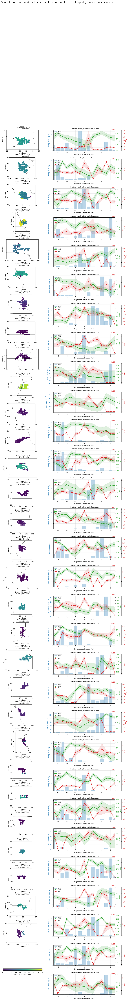

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# -------------------------------------------------
# 1. Choose largest grouped events
# -------------------------------------------------
event_sizes = pulse_df.groupby("group_id").size().sort_values(ascending=False)
top_events = event_sizes.head(30).index   # <- changed from 5 to 10

df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])

pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

WINDOW_DAYS = 7
n_events = len(top_events)

# -------------------------------------------------
# 2. Figure + outer layout
# -------------------------------------------------
fig = plt.figure(figsize=(14, 3.6 * n_events))   # taller figure for 10 rows
outer = gridspec.GridSpec(n_events, 1, hspace=0.42)

map_axes = []
ts_axes = []
last_sc = None

# global color scale for map timing
all_hours = (
    (
        pulse_df.loc[pulse_df["group_id"].isin(top_events), "datetime"]
        - pulse_df.loc[pulse_df["group_id"].isin(top_events)]
          .groupby("group_id")["datetime"].transform("min")
    )
    .dt.total_seconds() / 3600
)

vmin_time = 0
vmax_time = all_hours.max()

for row, eid in enumerate(top_events):

    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2,
        subplot_spec=outer[row],
        width_ratios=[1.0, 1.55],
        wspace=0.22
    )

    # -------------------------------------------------
    # Event data
    # -------------------------------------------------
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    t0 = event_pulses["datetime"].min()

    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    cell_daily = (
        sub.groupby(["grid_lat", "grid_lon", "lag_day"])
        .agg(
            precip=("h_precip_mm", "sum"),
            wfps=("WFPS_c", "mean"),
            no2=("no2_mean", "mean")
        )
        .reset_index()
    )

    event_daily = (
        cell_daily.groupby("lag_day")
        .agg(
            precip_mean=("precip", "mean"),
            precip_std=("precip", "std"),
            wfps_mean=("wfps", "mean"),
            wfps_std=("wfps", "std"),
            no2_mean=("no2", "mean"),
            no2_std=("no2", "std")
        )
        .reset_index()
    )

    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left").fillna(0)

    # -------------------------------------------------
    # Left panel: map
    # -------------------------------------------------
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)

    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5
    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 0.1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 0.1, 1)
    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")

    sc = ax_map.scatter(
        event_pulses["grid_lon"],
        event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"],
        cmap="viridis",
        vmin=vmin_time,
        vmax=vmax_time,
        s=38,
        marker="s",
        alpha=0.9,
        transform=ccrs.PlateCarree()
    )
    last_sc = sc

    ax_map.set_title(
        f"Event {eid} footprint\nn = {event_sizes.loc[eid]} pulse cells",
        fontsize=10
    )

    # -------------------------------------------------
    # Right panel: time series
    # -------------------------------------------------
    ax_ts = fig.add_subplot(inner[1])
    ts_axes.append(ax_ts)

    ax_ts.bar(
        event_daily["lag_day"],
        event_daily["precip_mean"],
        alpha=0.30,
        width=0.8,
        color="tab:blue",
        edgecolor="tab:blue",
        label="Precip"
    )
    ax_ts.set_ylabel("Precip (mm day$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1)
    ax_ts.grid(True, alpha=0.25)

    ax_wfps = ax_ts.twinx()
    ax_wfps.plot(
        event_daily["lag_day"],
        event_daily["wfps_mean"],
        marker="o",
        linewidth=2,
        color="tab:green",
        label="WFPS"
    )
    ax_wfps.fill_between(
        event_daily["lag_day"],
        event_daily["wfps_mean"] - event_daily["wfps_std"],
        event_daily["wfps_mean"] + event_daily["wfps_std"],
        color="tab:green",
        alpha=0.15
    )
    ax_wfps.set_ylabel("WFPS", color="tab:green")
    ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    ax_no2.spines["right"].set_position(("outward", 45))
    ax_no2.plot(
        event_daily["lag_day"],
        event_daily["no2_mean"],
        marker="s",
        linestyle="--",
        linewidth=2,
        color="tab:red",
        label="NO$_2$"
    )
    ax_no2.fill_between(
        event_daily["lag_day"],
        event_daily["no2_mean"] - event_daily["no2_std"],
        event_daily["no2_mean"] + event_daily["no2_std"],
        color="tab:red",
        alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xlabel("Days relative to event start")
    ax_ts.set_title("Event-centered hydrochemical evolution", fontsize=10)

    handles1, labels1 = ax_ts.get_legend_handles_labels()
    handles2, labels2 = ax_wfps.get_legend_handles_labels()
    handles3, labels3 = ax_no2.get_legend_handles_labels()
    ax_ts.legend(
        handles1 + handles2 + handles3,
        labels1 + labels2 + labels3,
        loc="upper left",
        fontsize=8,
        frameon=True
    )

# -------------------------------------------------
# 3. Colorbar for map column only
# -------------------------------------------------
cbar = fig.colorbar(
    last_sc,
    ax=map_axes,
    orientation="horizontal",
    fraction=0.03,
    pad=0.03
)
cbar.set_label("Hours since event start")

# -------------------------------------------------
# 4. Title + layout
# -------------------------------------------------
fig.suptitle(
    f"Spatial footprints and hydrochemical evolution of the {n_events} largest grouped pulse events",
    fontsize=18,
    y=0.995
)

plt.tight_layout(rect=[0.03, 0.03, 0.98, 0.975])
plt.show()

In [38]:
event_sizes = pulse_df.groupby("group_id").size().rename("n_cells")

event_choice_df = event_sm_frac.merge(event_sizes, left_index=True, right_index=True)
event_choice_df = event_choice_df.sort_values("n_cells", ascending=False)

In [41]:
event_choice_df.head(50)

,Decreasing,Increasing,dominant_class,dominant_frac,coherent,n_cells
group_id,,,,,,
793,1.000000,0.000000,Decreasing,1.000000,True,118
1786,0.973913,0.026087,Decreasing,0.973913,True,115
1974,0.917431,0.082569,Decreasing,0.917431,True,109
5118,0.695652,0.304348,Decreasing,0.695652,False,92
3701,0.023810,0.976190,Increasing,0.976190,True,84
2843,1.000000,0.000000,Decreasing,1.000000,True,82
1504,0.000000,1.000000,Increasing,1.000000,True,81
5293,1.000000,0.000000,Decreasing,1.000000,True,79
5485,0.285714,0.714286,Increasing,0.714286,True,77


/tmp/ipykernel_265453/368122872.py:253: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.02, 1, 0.96])


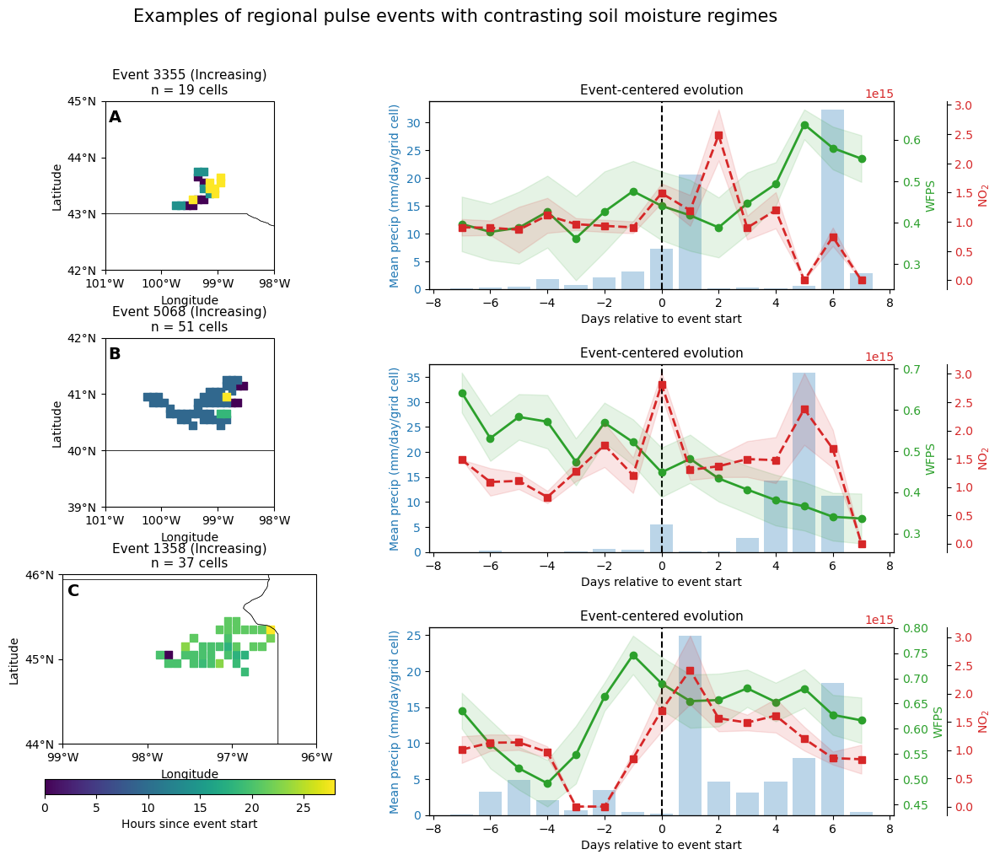

In [43]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import numpy as np
import pandas as pd

events_to_plot = [3355, 5068, 1358] 
WINDOW_DAYS = 7

fig = plt.figure(figsize=(13, 11))
outer = gridspec.GridSpec(3, 1, hspace=0.4)

map_axes = []
last_sc = None

for row, eid in enumerate(events_to_plot):

    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2,
        subplot_spec=outer[row],
        width_ratios=[1.0, 1.6],
        wspace=0.25
    )

    # -----------------------------
    # Event data
    # -----------------------------
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    t0 = event_pulses["datetime"].min()

    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )
    # -----------------------------
    # Dominant soil texture in this event
    # -----------------------------
    event_soils = (
        pulse_df.loc[pulse_df["group_id"] == eid, ["grid_lat", "grid_lon", "dominant_texture"]]
        .drop_duplicates(subset=["grid_lat", "grid_lon"])
        .dropna(subset=["dominant_texture"])
        .copy()
    )
    
    if len(event_soils) > 0:
        soil_counts = event_soils["dominant_texture"].value_counts()
        dominant_soil = soil_counts.index[0]
        dominant_soil_frac = soil_counts.iloc[0] / soil_counts.sum()
    else:
        dominant_soil = "Unknown"
        dominant_soil_frac = np.nan

    # -----------------------------
    # Full time series
    # -----------------------------
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()

    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    # cell → daily
    cell_daily = (
        sub.groupby(["grid_lat", "grid_lon", "lag_day"])
        .agg(
            precip=("h_precip_mm", "sum"),
            wfps=("WFPS_c", "mean"),
            no2=("no2_mean", "mean")
        )
        .reset_index()
    )

    # event average
    event_daily = (
        cell_daily.groupby("lag_day")
        .agg(
            precip_mean=("precip", "mean"),
            wfps_mean=("wfps", "mean"),
            wfps_std=("wfps", "std"),
            no2_mean=("no2", "mean"),
            no2_std=("no2", "std")
        )
        .reset_index()
    )

    # fill missing days
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left").fillna(0)

    # -----------------------------
    # LEFT: MAP
    # -----------------------------
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)

    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max])

    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.coastlines(linewidth=0.4)

    sc = ax_map.scatter(
        event_pulses["grid_lon"],
        event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"],
        cmap="viridis",
        s=40,
        marker="s",
        transform=ccrs.PlateCarree()
    )
    last_sc = sc

    ax_map.set_title(
        f"Event {eid} ({'Decreasing' if eid==2275 else 'Increasing'})\n"
        f"n = {len(event_cells)} cells",
        fontsize=11
    )

    ax_map.set_xlabel("Lon")
    ax_map.set_ylabel("Lat")
    # Panel labels (A, B, C)
    panel_labels = ["A", "B", "C"]
    ax_map.text(
        0.02, 0.95,
        panel_labels[row],
        transform=ax_map.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top"
    )
    
    # set ticks
    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1)
    
    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    
    # format as °W / °N
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    
    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")

    # -----------------------------
    # RIGHT: TIME SERIES
    # -----------------------------
    ax_ts = fig.add_subplot(inner[1])

    # precip (blue bars)
    ax_ts.bar(
        event_daily["lag_day"],
        event_daily["precip_mean"],
        color="tab:blue",
        alpha=0.3,
        label="Precip"
    )
    ax_ts.set_ylabel("Mean precip (mm/day/grid cell)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")

    ax_ts.axvline(0, color="k", linestyle="--")

    # WFPS (green)
    # -----------------------------
    # WFPS (green) with ± std
    # -----------------------------
    ax_wfps = ax_ts.twinx()
    
    ax_wfps.plot(
        event_daily["lag_day"],
        event_daily["wfps_mean"],
        color="tab:green",
        marker="o",
        label="WFPS",
        linewidth=2
    )
    
    ax_wfps.fill_between(
        event_daily["lag_day"],
        event_daily["wfps_mean"] - event_daily["wfps_std"],
        event_daily["wfps_mean"] + event_daily["wfps_std"],
        color="tab:green",
        alpha=0.12
    )
    
    ax_wfps.set_ylabel("WFPS", color="tab:green")
    ax_wfps.tick_params(axis="y", labelcolor="tab:green")
    
    
    # -----------------------------
    # NO2 (red) with ± std
    # -----------------------------
    ax_no2 = ax_ts.twinx()
    ax_no2.spines["right"].set_position(("outward", 45))
    
    ax_no2.plot(
        event_daily["lag_day"],
        event_daily["no2_mean"],
        color="tab:red",
        linestyle="--",
        marker="s",
        label="NO$_2$",
        linewidth=2
    )
    
    ax_no2.fill_between(
        event_daily["lag_day"],
        event_daily["no2_mean"] - event_daily["no2_std"],
        event_daily["no2_mean"] + event_daily["no2_std"],
        color="tab:red",
        alpha=0.12
    )
    
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlabel("Days relative to event start")
    ax_ts.set_title("Event-centered evolution", fontsize=11)

# -----------------------------
# Colorbar (maps only)
# -----------------------------
cbar = fig.colorbar(
    last_sc,
    ax=map_axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.05
)
cbar.set_label("Hours since event start")

# -----------------------------
# Title
# -----------------------------
fig.suptitle(
    "Examples of regional pulse events with contrasting soil moisture regimes",
    fontsize=15,
    y=0.98
)
plt.tight_layout(rect=[0, 0.02, 1, 0.96])
plt.show()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


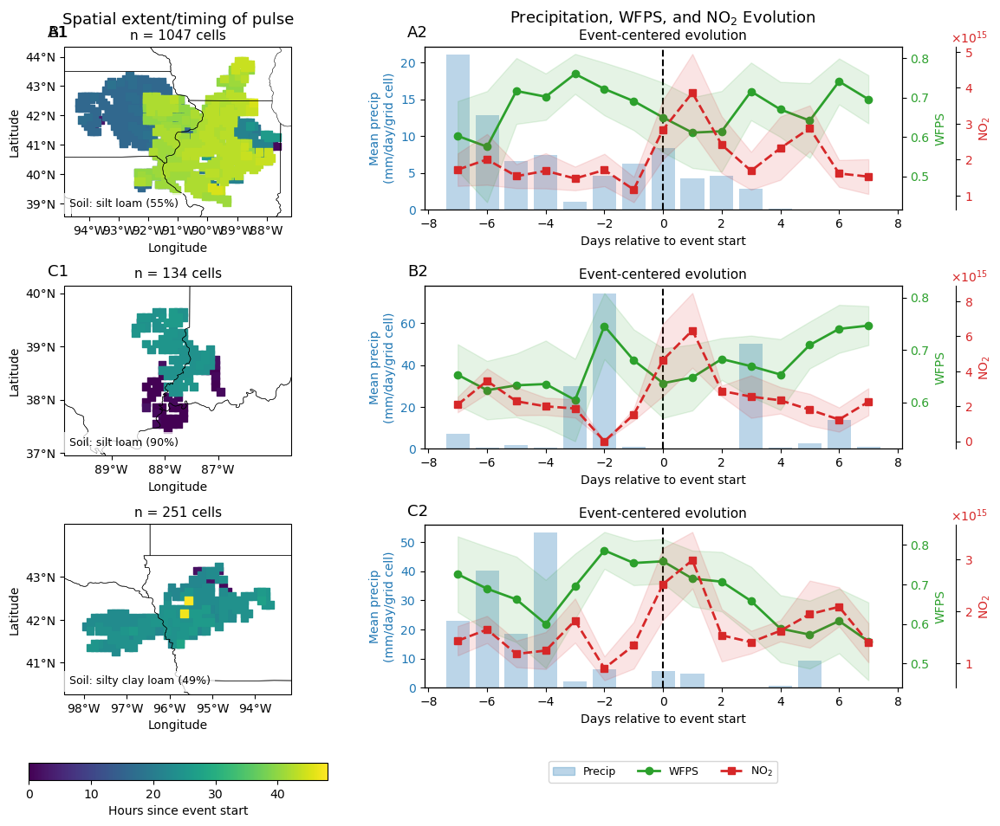

In [51]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import numpy as np
import pandas as pd

# -------------------------------------------------
# Settings
# -------------------------------------------------
events_to_plot = [8004, 4682, 8285]
WINDOW_DAYS = 7
row_labels = ["A", "B", "C"]

df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])

pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

fig = plt.figure(figsize=(13, 11))

# -------------------------------------------------
# OUTER GRID: 2 columns
# -------------------------------------------------
outer = gridspec.GridSpec(
    1, 2,
    width_ratios=[1.0, 1.6],
    wspace=0.25
)

# left column: 3 maps + 1 colorbar row
left_gs = gridspec.GridSpecFromSubplotSpec(
    4, 1,
    subplot_spec=outer[0],
    height_ratios=[1, 1, 1, 0.10],
    hspace=0.52
)

# right column: 3 time series + 1 legend row
right_gs = gridspec.GridSpecFromSubplotSpec(
    4, 1,
    subplot_spec=outer[1],
    height_ratios=[1, 1, 1, 0.10],
    hspace=0.60
)

map_axes = []
ts_axes = []
last_sc = None

# -------------------------------------------------
# Global color scale
# -------------------------------------------------
all_event_pulses = pulse_df[pulse_df["group_id"].isin(events_to_plot)].copy()
all_event_pulses["hours_since_start"] = (
    all_event_pulses["datetime"]
    - all_event_pulses.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600

vmin_time = 0
vmax_time = all_event_pulses["hours_since_start"].max()

for row, eid in enumerate(events_to_plot):

    # -----------------------------
    # Event data
    # -----------------------------
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    t0 = event_pulses["datetime"].min()

    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    if "event_sm_frac" in globals():
        event_type = event_sm_frac.loc[eid, "dominant_class"]
    else:
        event_type = "Unknown"

    event_soils = (
        pulse_df.loc[
            pulse_df["group_id"] == eid,
            ["grid_lat", "grid_lon", "dominant_texture"]
        ]
        .drop_duplicates(subset=["grid_lat", "grid_lon"])
        .dropna(subset=["dominant_texture"])
        .copy()
    )

    if len(event_soils) > 0:
        soil_counts = event_soils["dominant_texture"].value_counts()
        dominant_soil = soil_counts.index[0]
        dominant_soil_frac = soil_counts.iloc[0] / soil_counts.sum()
    else:
        dominant_soil = "Unknown"
        dominant_soil_frac = np.nan

    # -----------------------------
    # Full time series
    # -----------------------------
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    cell_daily = (
        sub.groupby(["grid_lat", "grid_lon", "lag_day"])
        .agg(
            precip=("h_precip_mm", "sum"),
            wfps=("WFPS_c", "mean"),
            no2=("no2_mean", "mean")
        )
        .reset_index()
    )

    event_daily = (
        cell_daily.groupby("lag_day")
        .agg(
            precip_mean=("precip", "mean"),
            wfps_mean=("wfps", "mean"),
            wfps_std=("wfps", "std"),
            no2_mean=("no2", "mean"),
            no2_std=("no2", "std")
        )
        .reset_index()
    )

    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left").fillna(0)

    # -----------------------------
    # LEFT: MAP
    # -----------------------------
    ax_map = fig.add_subplot(left_gs[row], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)

    # make all map panels the same visible box shape
    ax_map.set_box_aspect(0.75)   # try 0.75 to 0.9 depending on what looks best
    map_axes.append(ax_map)

    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.coastlines(linewidth=0.4)

    xticks = np.arange(np.ceil(lon_min), np.floor(lon_max) + 1, 1)
    yticks = np.arange(np.ceil(lat_min), np.floor(lat_max) + 1, 1)

    if len(xticks) > 0:
        ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    if len(yticks) > 0:
        ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())

    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())

    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")

    sc = ax_map.scatter(
        event_pulses["grid_lon"],
        event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"],
        cmap="viridis",
        vmin=vmin_time,
        vmax=vmax_time,
        s=40,
        marker="s",
        transform=ccrs.PlateCarree()
    )
    last_sc = sc

    ax_map.set_title(f"n = {len(event_cells)} cells", fontsize=11)

    soil_text = (
        f"Soil: {dominant_soil} ({dominant_soil_frac:.0%})"
        if pd.notna(dominant_soil_frac)
        else "Soil: Unknown"
    )
    ax_map.text(
        0.02, 0.06, soil_text,
        transform=ax_map.transAxes,
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.75, edgecolor="none")
    )

    # -----------------------------
    # RIGHT: TIME SERIES
    # -----------------------------
    ax_ts = fig.add_subplot(right_gs[row])
    ts_axes.append(ax_ts)

    ax_ts.bar(
        event_daily["lag_day"],
        event_daily["precip_mean"],
        color="tab:blue",
        alpha=0.3
    )
    ax_ts.set_ylabel("Mean precip\n(mm/day/grid cell)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--")

    ax_wfps = ax_ts.twinx()
    ax_wfps.plot(
        event_daily["lag_day"], event_daily["wfps_mean"],
        color="tab:green", marker="o", linewidth=2
    )
    ax_wfps.fill_between(
        event_daily["lag_day"],
        event_daily["wfps_mean"] - event_daily["wfps_std"],
        event_daily["wfps_mean"] + event_daily["wfps_std"],
        color="tab:green", alpha=0.12
    )
    ax_wfps.set_ylabel("WFPS", color="tab:green")
    ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    ax_no2.spines["right"].set_position(("outward", 45))
    ax_no2.plot(
        event_daily["lag_day"], event_daily["no2_mean"],
        color="tab:red", linestyle="--", marker="s", linewidth=2
    )
    ax_no2.fill_between(
        event_daily["lag_day"],
        event_daily["no2_mean"] - event_daily["no2_std"],
        event_daily["no2_mean"] + event_daily["no2_std"],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    formatter = mticker.ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((0, 0))
    ax_no2.yaxis.set_major_formatter(formatter)
    ax_no2.yaxis.get_offset_text().set_color("tab:red")
    ax_no2.yaxis.get_offset_text().set_x(1.18)

    ax_ts.set_xlabel("Days relative to event start")
    ax_ts.set_title("Event-centered evolution", fontsize=11)

# -------------------------------------------------
# Bottom left: colorbar axis
# -------------------------------------------------
cax = fig.add_subplot(left_gs[3])
cbar = fig.colorbar(last_sc, cax=cax, orientation="horizontal")
cbar.set_label("Hours since event start")

# -------------------------------------------------
# Bottom right: legend axis
# -------------------------------------------------
lax = fig.add_subplot(right_gs[3])
lax.axis("off")

legend_handles = [
    Patch(facecolor="tab:blue", edgecolor="tab:blue", alpha=0.3, label="Precip"),
    Line2D([0], [0], color="tab:green", marker="o", linewidth=2, label="WFPS"),
    Line2D([0], [0], color="tab:red", marker="s", linestyle="--", linewidth=2, label="NO$_2$")
]

lax.legend(
    handles=legend_handles,
    loc="center",
    ncol=3,
    frameon=True,
    fontsize=9
)

# -------------------------------------------------
# Column titles
# -------------------------------------------------
fig.canvas.draw()

map_pos = map_axes[0].get_position()
ts_pos = ts_axes[0].get_position()

fig.text(
    map_pos.x0 + map_pos.width / 2,
    map_pos.y1 + 0.02,
    "Spatial extent/timing of pulse",
    ha="center", va="bottom", fontsize=13
)

fig.text(
    ts_pos.x0 + ts_pos.width / 2,
    ts_pos.y1 + 0.02,
    "Precipitation, WFPS, and NO$_2$ Evolution",
    ha="center", va="bottom", fontsize=13
)

# -------------------------------------------------
# Panel labels outside axes
# -------------------------------------------------
# for row, (ax_map, ax_ts) in enumerate(zip(map_axes, ts_axes)):
#     map_pos = ax_map.get_position()
#     ts_pos = ax_ts.get_position()

#     fig.text(map_pos.x0, map_pos.y1 + 0.005, f"{row_labels[row]}1",
#              ha="left", va="bottom", fontsize=13)
#     fig.text(ts_pos.x0, ts_pos.y1 + 0.005, f"{row_labels[row]}2",
#              ha="left", va="bottom", fontsize=13)

# fixed x positions for consistent alignment
left_label_x  = min(ax.get_position().x0 for ax in map_axes) - 0.015
right_label_x = min(ax.get_position().x0 for ax in ts_axes)  - 0.015

for row, (ax_map, ax_ts) in enumerate(zip(map_axes, ts_axes)):
    map_pos = ax_map.get_position()
    ts_pos = ax_ts.get_position()

    fig.text(
        left_label_x,
        map_pos.y1 + 0.006,
        f"{row_labels[row]}1",
        ha="left",
        va="bottom",
        fontsize=13
    )

    fig.text(
        right_label_x,
        ts_pos.y1 + 0.006,
        f"{row_labels[row]}2",
        ha="left",
        va="bottom",
        fontsize=13
    )

plt.show()

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


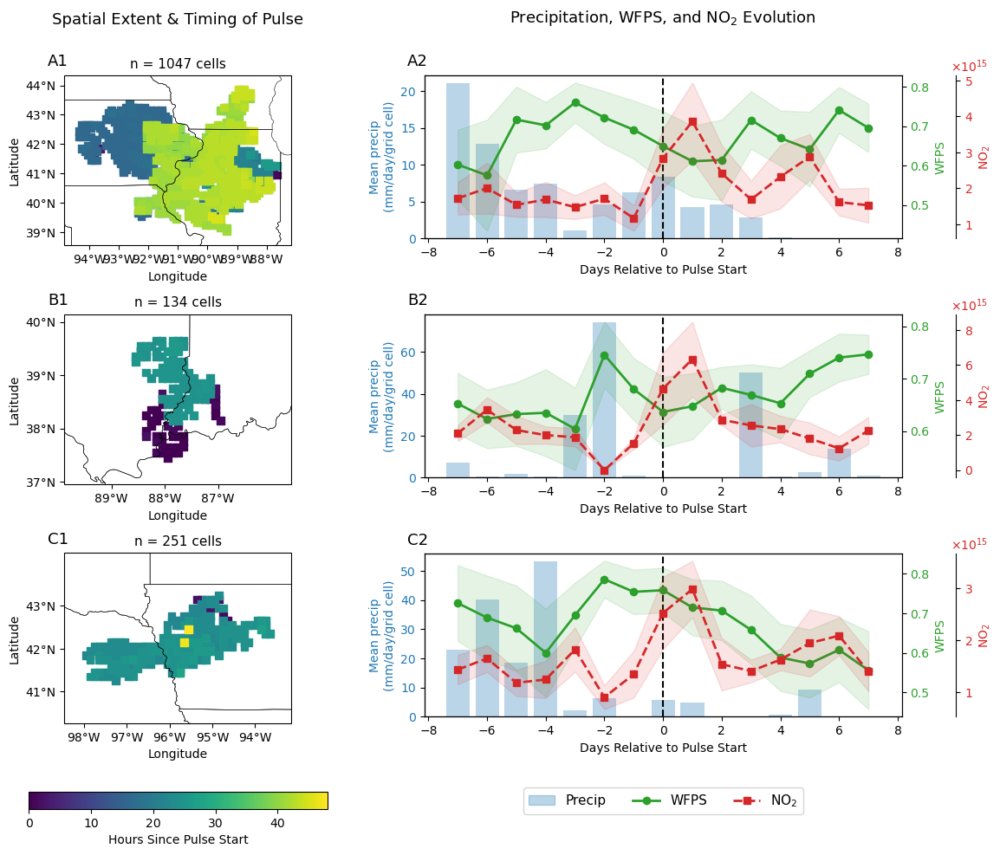

In [52]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import numpy as np
import pandas as pd

# -------------------------------------------------
# Settings
# -------------------------------------------------
events_to_plot = [8004, 4682, 8285]
WINDOW_DAYS = 7
row_labels = ["A", "B", "C"]

df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])

pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

fig = plt.figure(figsize=(13, 11))

# -------------------------------------------------
# OUTER GRID: 2 columns
# -------------------------------------------------
outer = gridspec.GridSpec(
    1, 2,
    width_ratios=[1.0, 1.6],
    wspace=0.25
)

# left column: 3 maps + 1 colorbar row
left_gs = gridspec.GridSpecFromSubplotSpec(
    4, 1,
    subplot_spec=outer[0],
    height_ratios=[1, 1, 1, 0.10],
    hspace=0.52
)

# right column: 3 time series + 1 legend row
right_gs = gridspec.GridSpecFromSubplotSpec(
    4, 1,
    subplot_spec=outer[1],
    height_ratios=[1, 1, 1, 0.10],
    hspace=0.60
)

map_axes = []
ts_axes = []
last_sc = None

# -------------------------------------------------
# Global color scale
# -------------------------------------------------
all_event_pulses = pulse_df[pulse_df["group_id"].isin(events_to_plot)].copy()
all_event_pulses["hours_since_start"] = (
    all_event_pulses["datetime"]
    - all_event_pulses.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600

vmin_time = 0
vmax_time = all_event_pulses["hours_since_start"].max()

for row, eid in enumerate(events_to_plot):

    # -----------------------------
    # Event data
    # -----------------------------
    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    t0 = event_pulses["datetime"].min()

    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    if "event_sm_frac" in globals():
        event_type = event_sm_frac.loc[eid, "dominant_class"]
    else:
        event_type = "Unknown"

    event_soils = (
        pulse_df.loc[
            pulse_df["group_id"] == eid,
            ["grid_lat", "grid_lon", "dominant_texture"]
        ]
        .drop_duplicates(subset=["grid_lat", "grid_lon"])
        .dropna(subset=["dominant_texture"])
        .copy()
    )

    if len(event_soils) > 0:
        soil_counts = event_soils["dominant_texture"].value_counts()
        dominant_soil = soil_counts.index[0]
        dominant_soil_frac = soil_counts.iloc[0] / soil_counts.sum()
    else:
        dominant_soil = "Unknown"
        dominant_soil_frac = np.nan

    # -----------------------------
    # Full time series
    # -----------------------------
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()

    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    cell_daily = (
        sub.groupby(["grid_lat", "grid_lon", "lag_day"])
        .agg(
            precip=("h_precip_mm", "sum"),
            wfps=("WFPS_c", "mean"),
            no2=("no2_mean", "mean")
        )
        .reset_index()
    )

    event_daily = (
        cell_daily.groupby("lag_day")
        .agg(
            precip_mean=("precip", "mean"),
            wfps_mean=("wfps", "mean"),
            wfps_std=("wfps", "std"),
            no2_mean=("no2", "mean"),
            no2_std=("no2", "std")
        )
        .reset_index()
    )

    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left").fillna(0)

    # -----------------------------
    # LEFT: MAP
    # -----------------------------
    ax_map = fig.add_subplot(left_gs[row], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)  # ← only once

    ax_map.set_box_aspect(0.75)

    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.coastlines(linewidth=0.4)

    xticks = np.arange(np.ceil(lon_min), np.floor(lon_max) + 1, 1)
    yticks = np.arange(np.ceil(lat_min), np.floor(lat_max) + 1, 1)

    if len(xticks) > 0:
        ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    if len(yticks) > 0:
        ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())

    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())

    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")

    sc = ax_map.scatter(
        event_pulses["grid_lon"],
        event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"],
        cmap="viridis",
        vmin=vmin_time,
        vmax=vmax_time,
        s=40,
        marker="s",
        transform=ccrs.PlateCarree()
    )
    last_sc = sc

    ax_map.set_title(f"n = {len(event_cells)} cells", fontsize=11)

    # soil_text = (
    #     f"Soil: {dominant_soil} ({dominant_soil_frac:.0%})"
    #     if pd.notna(dominant_soil_frac)
    #     else "Soil: Unknown"
    # )
    # ax_map.text(
    #     0.02, 0.06, soil_text,
    #     transform=ax_map.transAxes,
    #     fontsize=9,
    #     bbox=dict(facecolor="white", alpha=0.75, edgecolor="none")
    # )

    # -----------------------------
    # RIGHT: TIME SERIES
    # -----------------------------
    ax_ts = fig.add_subplot(right_gs[row])
    ts_axes.append(ax_ts)

    ax_ts.bar(
        event_daily["lag_day"],
        event_daily["precip_mean"],
        color="tab:blue",
        alpha=0.3
    )
    ax_ts.set_ylabel("Mean precip\n(mm/day/grid cell)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--")

    ax_wfps = ax_ts.twinx()
    ax_wfps.plot(
        event_daily["lag_day"], event_daily["wfps_mean"],
        color="tab:green", marker="o", linewidth=2
    )
    ax_wfps.fill_between(
        event_daily["lag_day"],
        event_daily["wfps_mean"] - event_daily["wfps_std"],
        event_daily["wfps_mean"] + event_daily["wfps_std"],
        color="tab:green", alpha=0.12
    )
    ax_wfps.set_ylabel("WFPS", color="tab:green")
    ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    ax_no2.spines["right"].set_position(("outward", 45))
    ax_no2.plot(
        event_daily["lag_day"], event_daily["no2_mean"],
        color="tab:red", linestyle="--", marker="s", linewidth=2
    )
    ax_no2.fill_between(
        event_daily["lag_day"],
        event_daily["no2_mean"] - event_daily["no2_std"],
        event_daily["no2_mean"] + event_daily["no2_std"],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    formatter = mticker.ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((0, 0))
    ax_no2.yaxis.set_major_formatter(formatter)
    ax_no2.yaxis.get_offset_text().set_color("tab:red")
    ax_no2.yaxis.get_offset_text().set_x(1.18)

    ax_ts.set_xlabel("Days Relative to Pulse Start")
    #ax_ts.set_title("Event-centered evolution", fontsize=11)

# -------------------------------------------------
# Bottom left: colorbar axis
# -------------------------------------------------
cax = fig.add_subplot(left_gs[3])
cbar = fig.colorbar(last_sc, cax=cax, orientation="horizontal")
cbar.set_label("Hours Since Pulse Start")

# -------------------------------------------------
# Bottom right: legend axis
# -------------------------------------------------
lax = fig.add_subplot(right_gs[3])
lax.axis("off")

legend_handles = [
    Patch(facecolor="tab:blue", edgecolor="tab:blue", alpha=0.3, label="Precip"),
    Line2D([0], [0], color="tab:green", marker="o", linewidth=2, label="WFPS"),
    Line2D([0], [0], color="tab:red", marker="s", linestyle="--", linewidth=2, label="NO$_2$")
]

lax.legend(
    handles=legend_handles,
    loc="center",
    ncol=3,
    frameon=True,
    fontsize=11
)

# -------------------------------------------------
# Column titles and panel labels
# -------------------------------------------------
fig.canvas.draw()

map_pos = map_axes[0].get_position()
ts_pos  = ts_axes[0].get_position()

fig.text(
    map_pos.x0 + map_pos.width / 2,
    map_pos.y1 + 0.05,
    "Spatial Extent & Timing of Pulse",
    ha="center", va="bottom", fontsize=13
)

fig.text(
    ts_pos.x0 + ts_pos.width / 2,
    ts_pos.y1 + 0.05,
    "Precipitation, WFPS, and NO$_2$ Evolution",
    ha="center", va="bottom", fontsize=13
)

# fixed x positions for consistent alignment
left_label_x  = min(ax.get_position().x0 for ax in map_axes) - 0.015
right_label_x = min(ax.get_position().x0 for ax in ts_axes)  - 0.015

for row, (ax_map, ax_ts) in enumerate(zip(map_axes, ts_axes)):
    map_pos = ax_map.get_position()
    ts_pos  = ax_ts.get_position()

    fig.text(
        left_label_x,
        map_pos.y1 + 0.006,
        f"{row_labels[row]}1",
        ha="left", va="bottom", fontsize=13
    )

    fig.text(
        right_label_x,
        ts_pos.y1 + 0.006,
        f"{row_labels[row]}2",
        ha="left", va="bottom", fontsize=13
    )
plt.savefig('/global/home/users/toireasamarie/Paper_Workflow/Paper Figures/examples_grouped_pulses.png', dpi=300)
plt.show()

In [39]:
import pandas as pd
import numpy as np

pulse_df = pulse_df.copy()
pulse_df["datetime"] = pd.to_datetime(pulse_df["datetime"])

if "datetime_local" in pulse_df.columns:
    pulse_df["datetime_local"] = pd.to_datetime(pulse_df["datetime_local"])

# -----------------------------------------
# 1. event summary from all grouped pulse cells
# -----------------------------------------
event_summary = (
    pulse_df.groupby("group_id")
    .agg(
        n_cells=("grid_lat", "count"),
        mean_no2=("no2_mean", "mean"),
        max_no2=("no2_mean", "max"),
        std_no2=("no2_mean", "std"),
        start_time=("datetime", "min"),
        duration_hours=("datetime", lambda x: (x.max() - x.min()).total_seconds() / 3600),
        mean_precip=("h_precip_mm", "mean"),
        centroid_lat=("grid_lat", "mean"),
        centroid_lon=("grid_lon", "mean"),
    )
    .reset_index()
)

# -----------------------------------------
# 2. mean NO2 specifically at event start
#    (using earliest time in each grouped event)
# -----------------------------------------
start_rows = pulse_df.merge(
    event_summary[["event_id", "start_time"]],
    left_on=["group_id", "datetime"],
    right_on=["group_id", "start_time"],
    how="inner"
)

start_no2 = (
    start_rows.groupby("group_id")
    .agg(
        mean_no2_start=("no2_mean", "mean"),
        max_no2_start=("no2_mean", "max"),
        n_start_cells=("grid_lat", "count")
    )
    .reset_index()
)

event_summary = event_summary.merge(start_no2, on="group_id", how="left")

# -----------------------------------------
# 3. timing fields
# -----------------------------------------
event_summary["start_month"] = event_summary["start_time"].dt.month
event_summary["start_month_name"] = event_summary["start_time"].dt.strftime("%b")
event_summary["start_hour_utc"] = event_summary["start_time"].dt.hour

# If local time exists, use it for hour-of-day
if "datetime_local" in pulse_df.columns:
    local_start_rows = pulse_df.merge(
        event_summary[["group_id", "start_time"]],
        left_on=["group_id", "datetime"],
        right_on=["group_id", "start_time"],
        how="inner"
    )
    
    local_start = (
        local_start_rows.groupby("group_id")
        .agg(start_time_local=("datetime_local", "min"))
        .reset_index()
    )
    
    event_summary = event_summary.merge(local_start, on="group_id", how="left")
    event_summary["start_hour_local"] = event_summary["start_time_local"].dt.hour

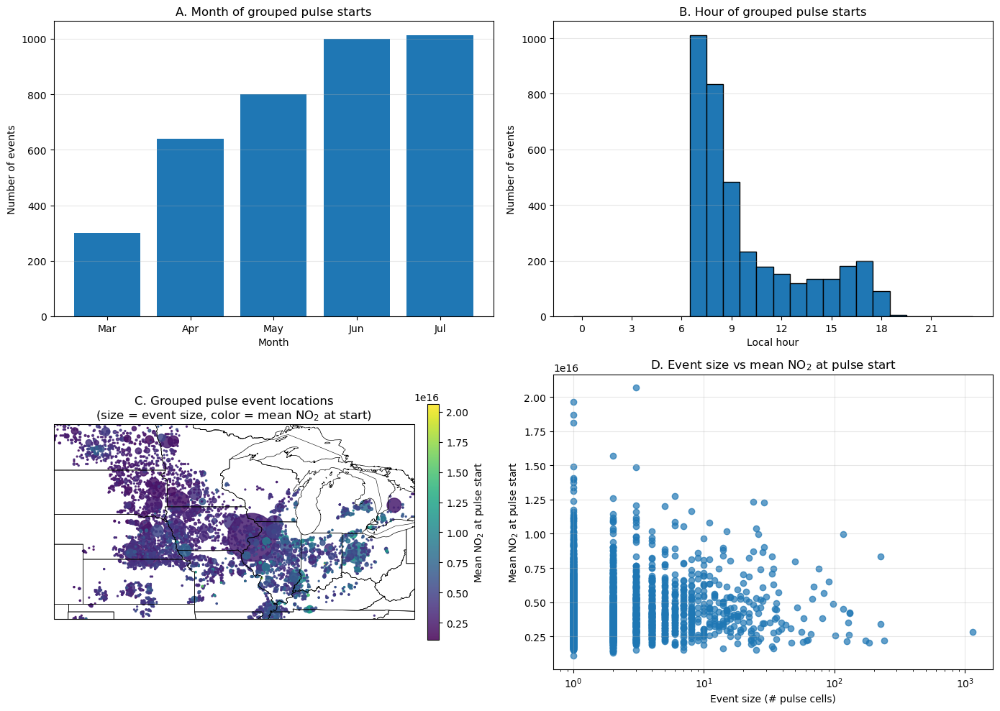

In [41]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig = plt.figure(figsize=(14, 10))

# -----------------------------
# Panel A: month of event starts
# -----------------------------
ax1 = plt.subplot(2, 2, 1)

month_order = ["Mar", "Apr", "May", "Jun", "Jul"]
month_counts = (
    event_summary["start_month_name"]
    .value_counts()
    .reindex(month_order)
)

ax1.bar(month_counts.index, month_counts.values)
ax1.set_title("A. Month of grouped pulse starts")
ax1.set_xlabel("Month")
ax1.set_ylabel("Number of events")
ax1.grid(axis="y", alpha=0.3)

# -----------------------------
# Panel B: hour of day
# -----------------------------
ax2 = plt.subplot(2, 2, 2)

hour_col = "start_hour_local" if "start_hour_local" in event_summary.columns else "start_hour_utc"

ax2.hist(event_summary[hour_col].dropna(), bins=np.arange(-0.5, 24.5, 1), edgecolor="black")
ax2.set_title("B. Hour of grouped pulse starts")
ax2.set_xlabel("Local hour" if hour_col == "start_hour_local" else "UTC hour")
ax2.set_ylabel("Number of events")
ax2.set_xticks(range(0, 24, 3))
ax2.grid(axis="y", alpha=0.3)

# -----------------------------
# Panel C: map of event centroids
# -----------------------------
ax3 = plt.subplot(2, 2, 3, projection=ccrs.PlateCarree())
ax3.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())
ax3.add_feature(cfeature.STATES, linewidth=0.5)
ax3.add_feature(cfeature.BORDERS, linewidth=0.4)
ax3.coastlines(linewidth=0.4)

sc = ax3.scatter(
    event_summary["centroid_lon"],
    event_summary["centroid_lat"],
    s=event_summary["n_cells"] * 2,
    c=event_summary["mean_no2_start"],
    cmap="viridis",
    alpha=0.85,
    transform=ccrs.PlateCarree()
)

cbar = plt.colorbar(sc, ax=ax3, shrink=0.8, pad=0.03)
cbar.set_label("Mean NO$_2$ at pulse start")

ax3.set_title("C. Grouped pulse event locations\n(size = event size, color = mean NO$_2$ at start)")

# -----------------------------
# Panel D: event size vs NO2 at start
# -----------------------------
ax4 = plt.subplot(2, 2, 4)

ax4.scatter(
    event_summary["n_cells"],
    event_summary["mean_no2_start"],
    alpha=0.7
)

ax4.set_xscale("log")
ax4.set_title("D. Event size vs mean NO$_2$ at pulse start")
ax4.set_xlabel("Event size (# pulse cells)")
ax4.set_ylabel("Mean NO$_2$ at pulse start")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Keeping 1438 events out of 3753


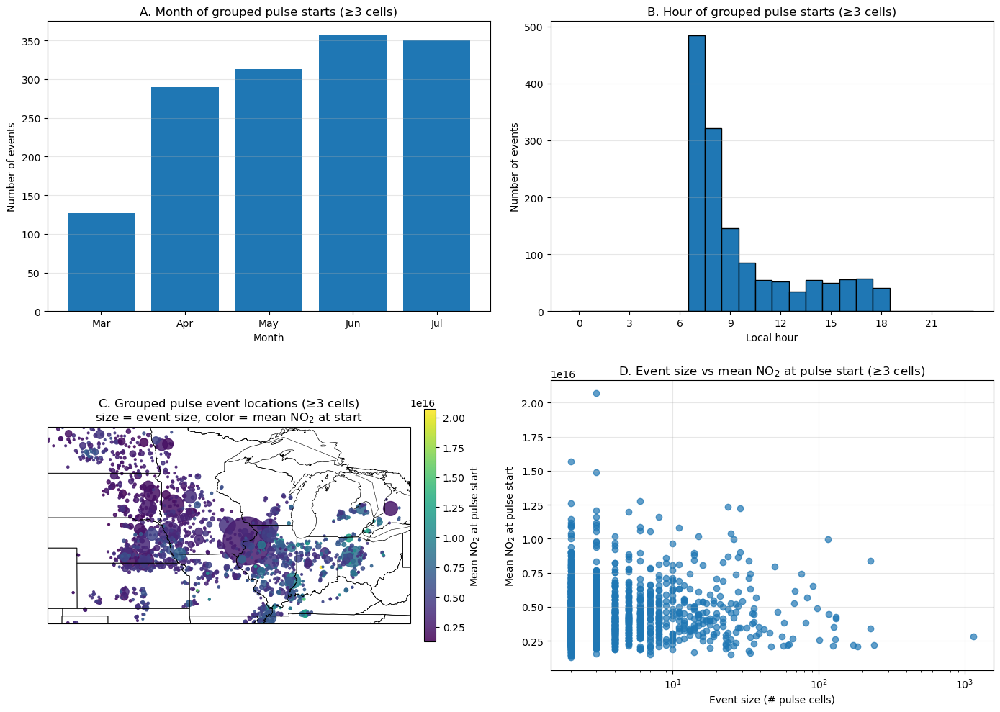

In [46]:
event_summary_filt = event_summary[event_summary["n_cells"] >= 2].copy()

print(f"Keeping {len(event_summary_filt)} events out of {len(event_summary)}")

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

fig = plt.figure(figsize=(14, 10))

# -----------------------------
# Panel A: month of event starts
# -----------------------------
ax1 = plt.subplot(2, 2, 1)

month_order = ["Mar", "Apr", "May", "Jun", "Jul"]
month_counts = (
    event_summary_filt["start_month_name"]
    .value_counts()
    .reindex(month_order)
    .fillna(0)
)

ax1.bar(month_counts.index, month_counts.values)
ax1.set_title("A. Month of grouped pulse starts (≥3 cells)")
ax1.set_xlabel("Month")
ax1.set_ylabel("Number of events")
ax1.grid(axis="y", alpha=0.3)

# -----------------------------
# Panel B: hour of day
# -----------------------------
ax2 = plt.subplot(2, 2, 2)

hour_col = "start_hour_local" if "start_hour_local" in event_summary_filt.columns else "start_hour_utc"

ax2.hist(
    event_summary_filt[hour_col].dropna(),
    bins=np.arange(-0.5, 24.5, 1),
    edgecolor="black"
)

ax2.set_title("B. Hour of grouped pulse starts (≥3 cells)")
ax2.set_xlabel("Local hour" if hour_col == "start_hour_local" else "UTC hour")
ax2.set_ylabel("Number of events")
ax2.set_xticks(range(0, 24, 3))
ax2.grid(axis="y", alpha=0.3)

# -----------------------------
# Panel C: map of event centroids
# -----------------------------
ax3 = plt.subplot(2, 2, 3, projection=ccrs.PlateCarree())
ax3.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())
ax3.add_feature(cfeature.STATES, linewidth=0.5)
ax3.add_feature(cfeature.BORDERS, linewidth=0.4)
ax3.coastlines(linewidth=0.4)

sc = ax3.scatter(
    event_summary_filt["centroid_lon"],
    event_summary_filt["centroid_lat"],
    s=event_summary_filt["n_cells"] * 2,
    c=event_summary_filt["mean_no2_start"],
    cmap="viridis",
    alpha=0.85,
    transform=ccrs.PlateCarree()
)

cbar = plt.colorbar(sc, ax=ax3, shrink=0.8, pad=0.03)
cbar.set_label("Mean NO$_2$ at pulse start")

ax3.set_title(
    "C. Grouped pulse event locations (≥3 cells)\n"
    "size = event size, color = mean NO$_2$ at start"
)

# -----------------------------
# Panel D: event size vs NO2 at start
# -----------------------------
ax4 = plt.subplot(2, 2, 4)

ax4.scatter(
    event_summary_filt["n_cells"],
    event_summary_filt["mean_no2_start"],
    alpha=0.7
)

ax4.set_xscale("log")
ax4.set_title("D. Event size vs mean NO$_2$ at pulse start (≥3 cells)")
ax4.set_xlabel("Event size (# pulse cells)")
ax4.set_ylabel("Mean NO$_2$ at pulse start")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Keeping 1438 events out of 3753


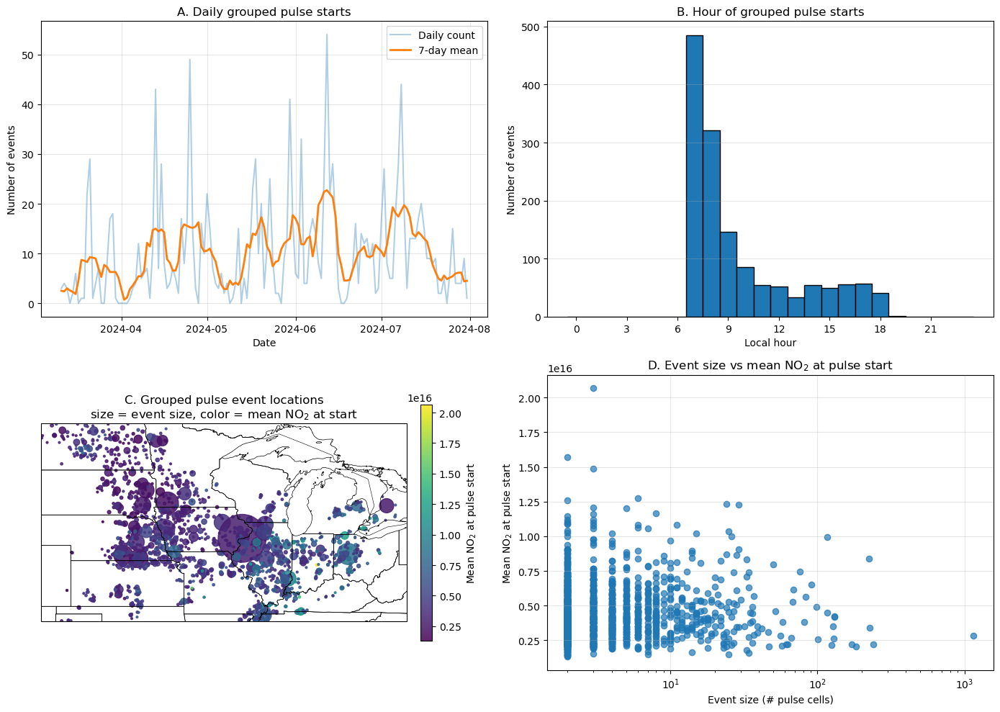

In [47]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd

# -------------------------------------------------
# Filter to meaningful events
# -------------------------------------------------
event_summary_filt = event_summary[event_summary["n_cells"] >= 2].copy()
event_summary_filt["start_time"] = pd.to_datetime(event_summary_filt["start_time"])

print(f"Keeping {len(event_summary_filt)} events out of {len(event_summary)}")

fig = plt.figure(figsize=(14, 10))

# -----------------------------
# Panel A: daily time series of grouped pulse starts
# -----------------------------
ax1 = plt.subplot(2, 2, 1)

event_summary_filt["start_date"] = event_summary_filt["start_time"].dt.floor("D")

daily_counts = (
    event_summary_filt.groupby("start_date")
    .size()
    .rename("n_events")
    .reset_index()
)

# full daily range so missing days show as zero
full_dates = pd.date_range(
    daily_counts["start_date"].min(),
    daily_counts["start_date"].max(),
    freq="D"
)

daily_counts = (
    pd.DataFrame({"start_date": full_dates})
    .merge(daily_counts, on="start_date", how="left")
    .fillna({"n_events": 0})
)

daily_counts["roll7"] = daily_counts["n_events"].rolling(7, center=True, min_periods=1).mean()

ax1.plot(daily_counts["start_date"], daily_counts["n_events"], alpha=0.35, label="Daily count")
ax1.plot(daily_counts["start_date"], daily_counts["roll7"], linewidth=2, label="7-day mean")

ax1.set_title("A. Daily grouped pulse starts")
ax1.set_xlabel("Date")
ax1.set_ylabel("Number of events")
ax1.grid(True, alpha=0.3)
ax1.legend()

# -----------------------------
# Panel B: hour of day
# -----------------------------
ax2 = plt.subplot(2, 2, 2)

hour_col = "start_hour_local" if "start_hour_local" in event_summary_filt.columns else "start_hour_utc"

ax2.hist(
    event_summary_filt[hour_col].dropna(),
    bins=np.arange(-0.5, 24.5, 1),
    edgecolor="black"
)

ax2.set_title("B. Hour of grouped pulse starts")
ax2.set_xlabel("Local hour" if hour_col == "start_hour_local" else "UTC hour")
ax2.set_ylabel("Number of events")
ax2.set_xticks(range(0, 24, 3))
ax2.grid(axis="y", alpha=0.3)

# -----------------------------
# Panel C: map of event centroids
# -----------------------------
ax3 = plt.subplot(2, 2, 3, projection=ccrs.PlateCarree())
ax3.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())
ax3.add_feature(cfeature.STATES, linewidth=0.5)
ax3.add_feature(cfeature.BORDERS, linewidth=0.4)
ax3.coastlines(linewidth=0.4)

sc = ax3.scatter(
    event_summary_filt["centroid_lon"],
    event_summary_filt["centroid_lat"],
    s=event_summary_filt["n_cells"] * 2,
    c=event_summary_filt["mean_no2_start"],
    cmap="viridis",
    alpha=0.85,
    transform=ccrs.PlateCarree()
)

cbar = plt.colorbar(sc, ax=ax3, shrink=0.8, pad=0.03)
cbar.set_label("Mean NO$_2$ at pulse start")

ax3.set_title(
    "C. Grouped pulse event locations\n"
    "size = event size, color = mean NO$_2$ at start"
)

# -----------------------------
# Panel D: event size vs NO2 at start
# -----------------------------
ax4 = plt.subplot(2, 2, 4)

ax4.scatter(
    event_summary_filt["n_cells"],
    event_summary_filt["mean_no2_start"],
    alpha=0.7
)

ax4.set_xscale("log")
ax4.set_title("D. Event size vs mean NO$_2$ at pulse start")
ax4.set_xlabel("Event size (# pulse cells)")
ax4.set_ylabel("Mean NO$_2$ at pulse start")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [48]:
hour_col = "start_hour_local" if "start_hour_local" in event_summary_filt.columns else "start_hour_utc"

event_no_morning = event_summary_filt[
    ~event_summary_filt[hour_col].between(7, 8)
].copy()

print(f"Removed {len(event_summary_filt) - len(event_no_morning)} events")

Removed 806 events


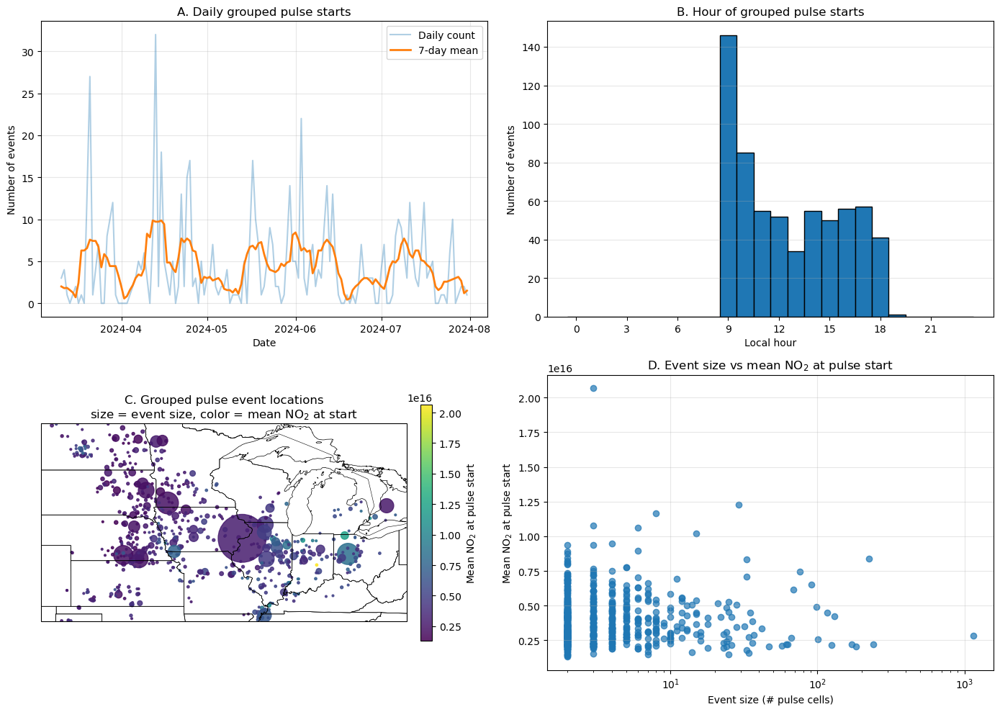

In [50]:

fig = plt.figure(figsize=(14, 10))

# -----------------------------
# Panel A: daily time series of grouped pulse starts
# -----------------------------
ax1 = plt.subplot(2, 2, 1)

event_no_morning["start_date"] = event_no_morning["start_time"].dt.floor("D")

daily_counts = (
    event_no_morning.groupby("start_date")
    .size()
    .rename("n_events")
    .reset_index()
)

# full daily range so missing days show as zero
full_dates = pd.date_range(
    daily_counts["start_date"].min(),
    daily_counts["start_date"].max(),
    freq="D"
)

daily_counts = (
    pd.DataFrame({"start_date": full_dates})
    .merge(daily_counts, on="start_date", how="left")
    .fillna({"n_events": 0})
)

daily_counts["roll7"] = daily_counts["n_events"].rolling(7, center=True, min_periods=1).mean()

ax1.plot(daily_counts["start_date"], daily_counts["n_events"], alpha=0.35, label="Daily count")
ax1.plot(daily_counts["start_date"], daily_counts["roll7"], linewidth=2, label="7-day mean")

ax1.set_title("A. Daily grouped pulse starts")
ax1.set_xlabel("Date")
ax1.set_ylabel("Number of events")
ax1.grid(True, alpha=0.3)
ax1.legend()

# -----------------------------
# Panel B: hour of day
# -----------------------------
ax2 = plt.subplot(2, 2, 2)

hour_col = "start_hour_local" if "start_hour_local" in event_no_morning.columns else "start_hour_utc"

ax2.hist(
    event_no_morning[hour_col].dropna(),
    bins=np.arange(-0.5, 24.5, 1),
    edgecolor="black"
)

ax2.set_title("B. Hour of grouped pulse starts")
ax2.set_xlabel("Local hour" if hour_col == "start_hour_local" else "UTC hour")
ax2.set_ylabel("Number of events")
ax2.set_xticks(range(0, 24, 3))
ax2.grid(axis="y", alpha=0.3)

# -----------------------------
# Panel C: map of event centroids
# -----------------------------
ax3 = plt.subplot(2, 2, 3, projection=ccrs.PlateCarree())
ax3.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())
ax3.add_feature(cfeature.STATES, linewidth=0.5)
ax3.add_feature(cfeature.BORDERS, linewidth=0.4)
ax3.coastlines(linewidth=0.4)

sc = ax3.scatter(
    event_no_morning["centroid_lon"],
    event_no_morning["centroid_lat"],
    s=event_no_morning["n_cells"] * 2,
    c=event_no_morning["mean_no2_start"],
    cmap="viridis",
    alpha=0.85,
    transform=ccrs.PlateCarree()
)

cbar = plt.colorbar(sc, ax=ax3, shrink=0.8, pad=0.03)
cbar.set_label("Mean NO$_2$ at pulse start")

ax3.set_title(
    "C. Grouped pulse event locations\n"
    "size = event size, color = mean NO$_2$ at start"
)

# -----------------------------
# Panel D: event size vs NO2 at start
# -----------------------------
ax4 = plt.subplot(2, 2, 4)

ax4.scatter(
    event_no_morning["n_cells"],
    event_no_morning["mean_no2_start"],
    alpha=0.7
)

ax4.set_xscale("log")
ax4.set_title("D. Event size vs mean NO$_2$ at pulse start")
ax4.set_xlabel("Event size (# pulse cells)")
ax4.set_ylabel("Mean NO$_2$ at pulse start")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
import pandas as pd
import numpy as np

# make sure precip is numeric
pulse_df = pulse_df.copy()
pulse_df["h_precip_mm"] = pd.to_numeric(pulse_df["h_precip_mm"], errors="coerce")

# ------------------------------------------
# A. total precip across all pulse rows
# ------------------------------------------
event_precip_total = (
    pulse_df.groupby("event_id")["h_precip_mm"]
    .sum(min_count=1)
    .rename("total_precip_mm")
    .reset_index()
)

# ------------------------------------------
# B. precip summed through time within each cell,
#    then averaged across cells in the event
# ------------------------------------------
cell_precip = (
    pulse_df.groupby(["event_id", "grid_lat", "grid_lon"])["h_precip_mm"]
    .sum(min_count=1)
    .reset_index(name="cell_total_precip_mm")
)

event_precip_cellmean = (
    cell_precip.groupby("event_id")["cell_total_precip_mm"]
    .mean()
    .rename("mean_cell_total_precip_mm")
    .reset_index()
)

# optional: median too
event_precip_cellmedian = (
    cell_precip.groupby("event_id")["cell_total_precip_mm"]
    .median()
    .rename("median_cell_total_precip_mm")
    .reset_index()
)

# merge onto event summary
event_summary = event_summary.merge(event_precip_total, on="event_id", how="left")
event_summary = event_summary.merge(event_precip_cellmean, on="event_id", how="left")
event_summary = event_summary.merge(event_precip_cellmedian, on="event_id", how="left")

In [52]:
event_summary_filt = event_summary[event_summary["n_cells"] >= 2].copy()
event_summary_filt["start_time"] = pd.to_datetime(event_summary_filt["start_time"])

print(f"Keeping {len(event_summary_filt)} events out of {len(event_summary)}")

Keeping 1438 events out of 3753


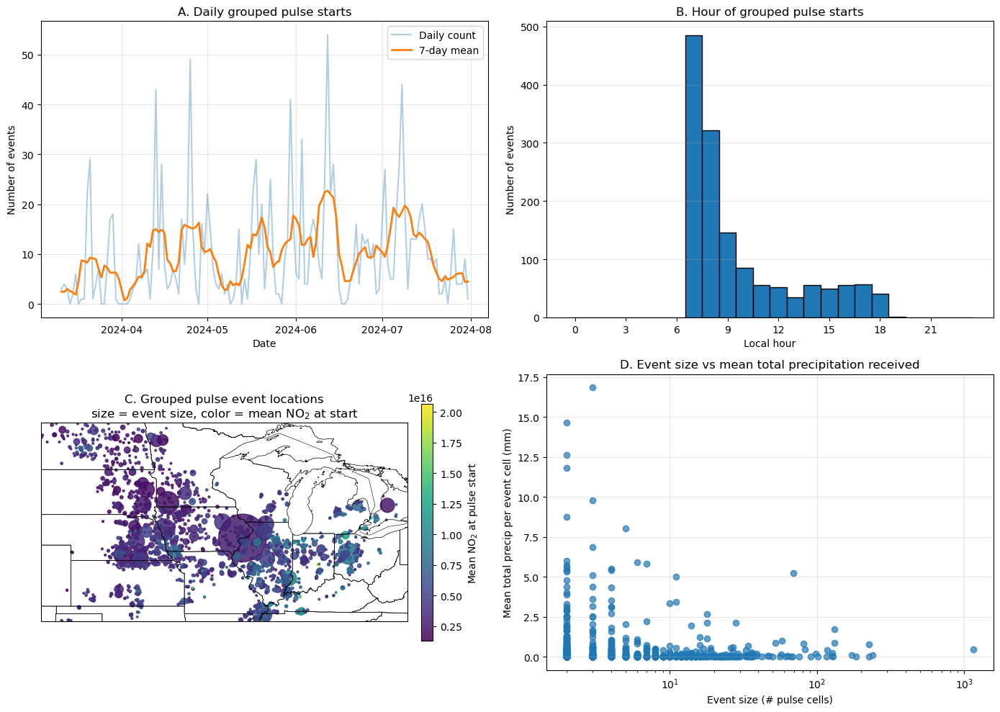

In [53]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd

fig = plt.figure(figsize=(14, 10))

# -----------------------------
# Panel A: daily time series of grouped pulse starts
# -----------------------------
ax1 = plt.subplot(2, 2, 1)

event_summary_filt["start_date"] = event_summary_filt["start_time"].dt.floor("D")

daily_counts = (
    event_summary_filt.groupby("start_date")
    .size()
    .rename("n_events")
    .reset_index()
)

full_dates = pd.date_range(
    daily_counts["start_date"].min(),
    daily_counts["start_date"].max(),
    freq="D"
)

daily_counts = (
    pd.DataFrame({"start_date": full_dates})
    .merge(daily_counts, on="start_date", how="left")
    .fillna({"n_events": 0})
)

daily_counts["roll7"] = daily_counts["n_events"].rolling(7, center=True, min_periods=1).mean()

ax1.plot(daily_counts["start_date"], daily_counts["n_events"], alpha=0.35, label="Daily count")
ax1.plot(daily_counts["start_date"], daily_counts["roll7"], linewidth=2, label="7-day mean")

ax1.set_title("A. Daily grouped pulse starts")
ax1.set_xlabel("Date")
ax1.set_ylabel("Number of events")
ax1.grid(True, alpha=0.3)
ax1.legend()

# -----------------------------
# Panel B: hour of day
# -----------------------------
ax2 = plt.subplot(2, 2, 2)

hour_col = "start_hour_local" if "start_hour_local" in event_summary_filt.columns else "start_hour_utc"

ax2.hist(
    event_summary_filt[hour_col].dropna(),
    bins=np.arange(-0.5, 24.5, 1),
    edgecolor="black"
)

ax2.set_title("B. Hour of grouped pulse starts")
ax2.set_xlabel("Local hour" if hour_col == "start_hour_local" else "UTC hour")
ax2.set_ylabel("Number of events")
ax2.set_xticks(range(0, 24, 3))
ax2.grid(axis="y", alpha=0.3)

# -----------------------------
# Panel C: map of event centroids
# -----------------------------
ax3 = plt.subplot(2, 2, 3, projection=ccrs.PlateCarree())
ax3.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())
ax3.add_feature(cfeature.STATES, linewidth=0.5)
ax3.add_feature(cfeature.BORDERS, linewidth=0.4)
ax3.coastlines(linewidth=0.4)

sc = ax3.scatter(
    event_summary_filt["centroid_lon"],
    event_summary_filt["centroid_lat"],
    s=event_summary_filt["n_cells"] * 2,
    c=event_summary_filt["mean_no2_start"],
    cmap="viridis",
    alpha=0.85,
    transform=ccrs.PlateCarree()
)

cbar = plt.colorbar(sc, ax=ax3, shrink=0.8, pad=0.03)
cbar.set_label("Mean NO$_2$ at pulse start")

ax3.set_title(
    "C. Grouped pulse event locations\n"
    "size = event size, color = mean NO$_2$ at start"
)

# -----------------------------
# Panel D: event size vs precipitation received
# -----------------------------
ax4 = plt.subplot(2, 2, 4)

ax4.scatter(
    event_summary_filt["n_cells"],
    event_summary_filt["mean_cell_total_precip_mm"],
    alpha=0.7
)

ax4.set_xscale("log")
ax4.set_title("D. Event size vs mean total precipitation received")
ax4.set_xlabel("Event size (# pulse cells)")
ax4.set_ylabel("Mean total precip per event cell (mm)")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [54]:
# remove events with very low precip per cell
event_summary_precip = event_summary_filt[
    event_summary_filt["mean_cell_total_precip_mm"] > 0.5
].copy()

print(f"Keeping {len(event_summary_precip)} events out of {len(event_summary_filt)} after precip filter")

Keeping 145 events out of 1438 after precip filter


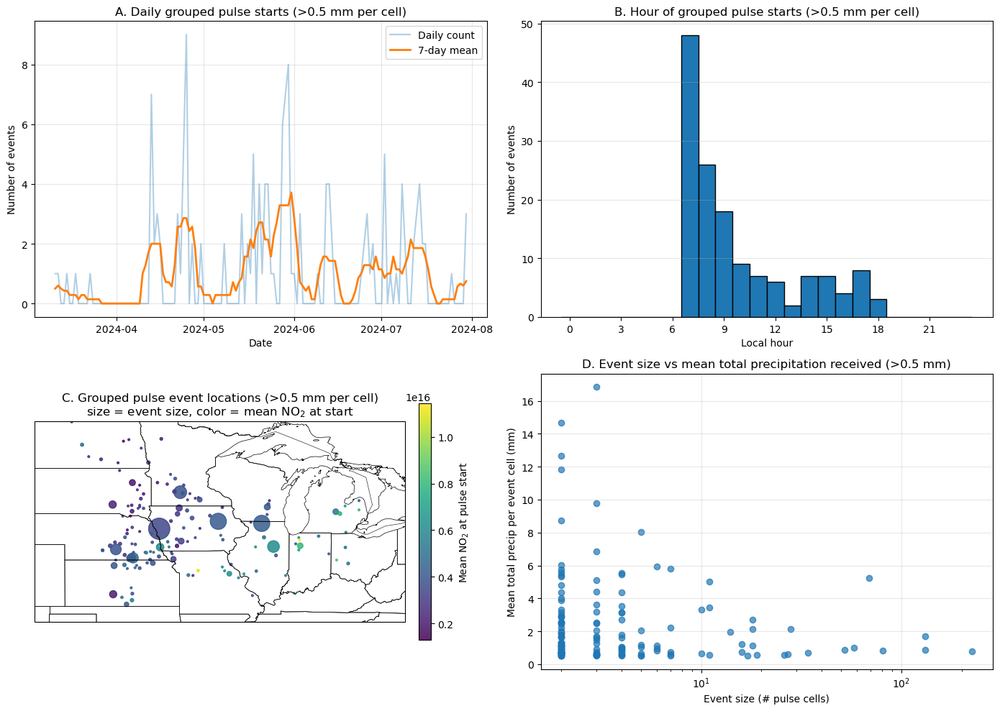

In [55]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd

fig = plt.figure(figsize=(14, 10))

# -----------------------------
# Panel A: daily time series of grouped pulse starts
# -----------------------------
ax1 = plt.subplot(2, 2, 1)

event_summary_precip["start_date"] = event_summary_precip["start_time"].dt.floor("D")

daily_counts = (
    event_summary_precip.groupby("start_date")
    .size()
    .rename("n_events")
    .reset_index()
)

full_dates = pd.date_range(
    daily_counts["start_date"].min(),
    daily_counts["start_date"].max(),
    freq="D"
)

daily_counts = (
    pd.DataFrame({"start_date": full_dates})
    .merge(daily_counts, on="start_date", how="left")
    .fillna({"n_events": 0})
)

daily_counts["roll7"] = daily_counts["n_events"].rolling(7, center=True, min_periods=1).mean()

ax1.plot(daily_counts["start_date"], daily_counts["n_events"], alpha=0.35, label="Daily count")
ax1.plot(daily_counts["start_date"], daily_counts["roll7"], linewidth=2, label="7-day mean")

ax1.set_title("A. Daily grouped pulse starts (>0.5 mm per cell)")
ax1.set_xlabel("Date")
ax1.set_ylabel("Number of events")
ax1.grid(True, alpha=0.3)
ax1.legend()

# -----------------------------
# Panel B: hour of day
# -----------------------------
ax2 = plt.subplot(2, 2, 2)

hour_col = "start_hour_local" if "start_hour_local" in event_summary_precip.columns else "start_hour_utc"

ax2.hist(
    event_summary_precip[hour_col].dropna(),
    bins=np.arange(-0.5, 24.5, 1),
    edgecolor="black"
)

ax2.set_title("B. Hour of grouped pulse starts (>0.5 mm per cell)")
ax2.set_xlabel("Local hour" if hour_col == "start_hour_local" else "UTC hour")
ax2.set_ylabel("Number of events")
ax2.set_xticks(range(0, 24, 3))
ax2.grid(axis="y", alpha=0.3)

# -----------------------------
# Panel C: map of event centroids
# -----------------------------
ax3 = plt.subplot(2, 2, 3, projection=ccrs.PlateCarree())
ax3.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())
ax3.add_feature(cfeature.STATES, linewidth=0.5)
ax3.add_feature(cfeature.BORDERS, linewidth=0.4)
ax3.coastlines(linewidth=0.4)

sc = ax3.scatter(
    event_summary_precip["centroid_lon"],
    event_summary_precip["centroid_lat"],
    s=event_summary_precip["n_cells"] * 2,
    c=event_summary_precip["mean_no2_start"],
    cmap="viridis",
    alpha=0.85,
    transform=ccrs.PlateCarree()
)

cbar = plt.colorbar(sc, ax=ax3, shrink=0.8, pad=0.03)
cbar.set_label("Mean NO$_2$ at pulse start")

ax3.set_title(
    "C. Grouped pulse event locations (>0.5 mm per cell)\n"
    "size = event size, color = mean NO$_2$ at start"
)

# -----------------------------
# Panel D: event size vs precipitation received
# -----------------------------
ax4 = plt.subplot(2, 2, 4)

ax4.scatter(
    event_summary_precip["n_cells"],
    event_summary_precip["mean_cell_total_precip_mm"],
    alpha=0.7
)

ax4.set_xscale("log")
ax4.set_title("D. Event size vs mean total precipitation received (>0.5 mm)")
ax4.set_xlabel("Event size (# pulse cells)")
ax4.set_ylabel("Mean total precip per event cell (mm)")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
event_summary_precip

,event_id,n_cells,mean_no2,max_no2,std_no2,start_time,duration_hours,mean_precip,centroid_lat,centroid_lon,...,n_start_cells,start_month,start_month_name,start_hour_utc,start_time_local,start_hour_local,total_precip_mm,mean_cell_total_precip_mm,median_cell_total_precip_mm,start_date
9,25,2,2.551022e+15,2.900958e+15,4.948841e+14,2024-03-12 14:00:00,0.0,1.127500,39.000000,-93.750000,...,2,3,Mar,14,2024-03-12 09:00:00,9,2.255,1.127500,1.1275,2024-03-12
13,44,26,3.059398e+15,3.777453e+15,4.621638e+14,2024-03-11 14:00:00,25.0,0.541731,37.784615,-98.915385,...,1,3,Mar,14,2024-03-11 09:00:00,9,14.085,0.563400,0.5300,2024-03-11
34,77,2,1.904529e+15,1.929400e+15,3.517240e+13,2024-03-15 18:00:00,0.0,1.670000,42.850000,-97.800000,...,2,3,Mar,18,2024-03-15 13:00:00,13,3.340,1.670000,1.6700,2024-03-15
53,138,6,2.275030e+15,2.668705e+15,3.185235e+14,2024-03-18 21:00:00,16.0,0.828333,40.916667,-94.783333,...,1,3,Mar,21,2024-03-18 16:00:00,16,2.485,0.828333,0.2250,2024-03-18
171,654,2,1.304282e+15,1.362256e+15,8.198701e+13,2024-03-23 16:00:00,0.0,0.897500,40.650000,-99.600000,...,2,3,Mar,16,2024-03-23 11:00:00,11,1.795,0.897500,0.8975,2024-03-23
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3483,13193,3,4.098247e+15,4.195265e+15,8.591129e+13,2024-07-16 22:00:00,0.0,6.848333,42.083333,-94.350000,...,3,7,Jul,22,2024-07-16 17:00:00,17,20.545,6.848333,5.4750,2024-07-16
3633,13583,3,2.459307e+15,2.633621e+15,1.814034e+14,2024-07-25 14:00:00,0.0,0.575000,44.916667,-95.416667,...,3,7,Jul,14,2024-07-25 09:00:00,9,1.725,0.575000,0.5800,2024-07-25
3722,13857,16,8.053464e+15,1.018131e+16,1.342482e+15,2024-07-30 13:00:00,0.0,1.233437,40.925000,-86.806250,...,16,7,Jul,13,2024-07-30 08:00:00,8,19.735,1.233437,0.8750,2024-07-30
3725,13869,2,7.105101e+15,7.178909e+15,1.043804e+14,2024-07-30 13:00:00,0.0,3.325000,40.650000,-86.900000,...,2,7,Jul,13,2024-07-30 09:00:00,9,6.650,3.325000,3.3250,2024-07-30
